# Лабораторная работа № 3
## Робастная линейная и логистическая регрессия

Данные: экспедиции на Эверест за 1921–2025 годы, выгрузка Himalayan Database 2.75 (2396 строк, 66 столбцов). Датасет один на оба задания:

* задание 1, линейная регрессия: сколько персонала нанимает экспедиция;
* задание 2, логистическая регрессия: дошла ли она до вершины.

Обозначения и номера формул взяты из книги Maronna, Martin, Yohai «Robust Statistics: Theory and Methods», главы 4, 5 и 7. Коды столбцов расшифрованы по справочнику Himalayan Database.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import quad
from scipy.optimize import check_grad, minimize
from sklearn.covariance import MinCovDet

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": "#e4e3df", "axes.edgecolor": "#b5b4ae",
})
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993"

## 0. Данные

### 0.1. Загрузка и первый взгляд

In [2]:
raw = pd.read_csv("everest-expeditions-himalayan-database-2.75.csv", encoding="utf-8-sig")
print(raw.shape)
raw.head(3)

(2396, 66)


,EXPID,PEAKID,YEAR,SEASON,HOST,ROUTE1,ROUTE2,ROUTE3,ROUTE4,NATION,...,ACCIDENTS,ACHIEVMENT,AGENCY,COMRTE,STDRTE,PRIMRTE,PRIMMEM,PRIMREF,PRIMID,CHKSUM
0,EVER88401,EVER,1988,4,1,S Col-SE Ridge,NaN,NaN,NaN,Belgium,...,"Dewaele exhausted, shocked, needed O2 and was ...",NaN,Mountain Travel,True,True,False,False,NaN,NaN,2449641
1,EVER88402,EVER,1988,4,1,SW Face (Bonington rte),NaN,NaN,NaN,S Korea,...,NaN,NaN,NaN,False,NaN,False,False,NaN,NaN,2449660
2,EVER89306,EVER,1989,3,2,N Col-N Face (Great Couloir),NaN,NaN,NaN,USA,...,NaN,NaN,NaN,False,False,False,False,NaN,NaN,2449938


### 0.2. Нужные столбцы

Из 66 столбцов берём 20. Ключом строки служит пара `YEAR` и `EXPID`: код записан двумя цифрами года, поэтому EVER21101 встречается и в 1921, и в 2021 году. `TOTHIRED` это нанятые, работавшие выше базового лагеря, `NOHIRED` отмечает, что их не было. Остальное переименовано в понятные названия. Коды сезона, страны и причины окончания расшифруем по справочнику базы, нулевую высоту заменим на пропуск.

In [3]:
columns = {"EXPID": "expedition_id", "YEAR": "year", "SEASON": "season", "HOST": "host", "NATION": "nation", "LEADERS": "leaders",
           "BCDATE": "basecamp_date", "SMTDATE": "highpoint_date", "TERMDATE": "termination_date", "TERMREASON": "termination_reason",
           "HIGHPOINT": "highpoint_metres", "TOTMEMBERS": "members", "MDEATHS": "member_deaths", "TOTHIRED": "hired_staff",
           "HDEATHS": "hired_staff_deaths", "NOHIRED": "no_hired", "O2USED": "oxygen_used", "COMRTE": "commercial_route", "STDRTE": "standard_route", "AGENCY": "trekking_agency"}
df = raw[list(columns)].rename(columns=columns)
df.head()

,expedition_id,year,season,host,nation,leaders,basecamp_date,highpoint_date,termination_date,termination_reason,highpoint_metres,members,member_deaths,hired_staff,hired_staff_deaths,no_hired,oxygen_used,commercial_route,standard_route,trekking_agency
0,EVER88401,1988,4,1,Belgium,Herman Detienne,1988-11-10,1988-12-22,NaN,6,8700,17,0,10,1,False,True,True,True,Mountain Travel
1,EVER88402,1988,4,1,S Korea,Park Young-Bae,1988-12-08,1989-01-10,1989-01-12,4,7800,11,0,7,0,False,False,False,NaN,NaN
2,EVER89306,1989,3,2,USA,Keith Brown,1989-08-21,1989-10-14,1989-10-15,4,7800,2,0,0,0,True,True,False,False,NaN
3,EVER89310,1989,3,2,Italy,Lorenzo Mazzoleni,1989-09-01,1989-09-25,1989-10-07,4,7500,4,0,0,0,True,False,False,NaN,Trekking International
4,EVER89305,1989,3,2,Switzerland,Norbert Joos,1989-08-17,1989-09-25,1989-10-01,5,8100,6,0,0,0,True,False,False,False,Sherpa Society


In [4]:
seasons = {1: "Spring", 2: "Summer", 3: "Autumn", 4: "Winter"}
hosts = {1: "Nepal", 2: "China"}
reasons = {0: "Unknown", 1: "Success (main peak)", 2: "Success (subpeak)", 3: "Success (claimed)", 4: "Bad weather",
           5: "Bad conditions", 6: "Accident", 7: "Illness, exhaustion", 8: "Lack of supplies", 9: "Lack of time",
           10: "Too difficult", 11: "Did not reach base camp", 12: "Did not attempt climb", 13: "Attempt rumoured", 14: "Other"}
df["season"], df["host"] = df["season"].map(seasons), df["host"].map(hosts)
df["termination_reason"] = df["termination_reason"].map(reasons)
df["highpoint_metres"] = df["highpoint_metres"].replace(0, np.nan)
df["termination_reason"].value_counts()

termination_reason
Success (main peak)        1535
Bad weather                 300
Other                       160
Illness, exhaustion         127
Bad conditions               85
Accident                     53
Lack of supplies             50
Too difficult                39
Did not attempt climb        15
Lack of time                 11
Unknown                       9
Success (claimed)             4
Attempt rumoured              4
Did not reach base camp       3
Success (subpeak)             1
Name: count, dtype: int64

In [5]:
pd.DataFrame({"тип": df.dtypes.astype(str), "пропуски": df.isna().sum(), "уникальных": df.nunique()})

,тип,пропуски,уникальных
expedition_id,object,0,2393
year,int64,0,80
season,object,0,4
host,object,0,2
nation,object,0,91
leaders,object,7,1551
basecamp_date,object,275,1048
highpoint_date,object,78,824
termination_date,object,504,744
termination_reason,object,0,15


In [6]:
df[["year", "members", "hired_staff", "highpoint_metres"]].describe()

,year,members,hired_staff,highpoint_metres
count,2396.000,2396.000,2396.000,2352.000
mean,2006.617,7.425,6.874,8427.849
std,12.551,7.629,9.770,810.098
min,1921.000,0.000,0.000,5100.000
25%,2001.000,2.000,1.000,8350.000
50%,2009.000,5.000,4.000,8849.000
75%,2016.000,11.000,9.000,8849.000
max,2025.000,99.000,99.000,8850.000


In [7]:
pd.crosstab(df["host"], df["season"])

season,Autumn,Spring,Summer,Winter
host,,,,
China,104,813,24,5
Nepal,130,1290,0,30


In [8]:
recent = df[df["year"] >= 2015]
pd.crosstab(recent["year"], recent["host"]).T

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
host,,,,,,,,,,,
China,21,29,29,22,27,3,1,2,3,6,7
Nepal,60,51,67,65,72,0,51,41,48,36,40


Пропусков в `members`, `hired_staff`, `year`, `season`, `oxygen_used` нет, но нули ещё не проверены. Справочник предупреждает, что ноль в `TOTHIRED` надо читать вместе с `NOHIRED`, к этому вернёмся в разделе 1.7. `members` означает участников, `hired_staff` нанятых людей, обычно шерпов. Оба столбца скошены вправо: третий квартиль 11 и 9 при максимуме 99.

Летних экспедиций 24, зимних 35. Для отдельных коэффициентов этого мало, поэтому сезон сводится к признаку «весна или нет». Из таблицы по годам видно, что с 2021 года почти все экспедиции шли с непальской стороны. Если не учесть сторону, тренд по годам смешается с этим переходом, поэтому добавляем признак `nepal`.

У `members` минимум ноль, смотрим на эти строки.

In [9]:
df.loc[df["members"] == 0, ["expedition_id", "year", "leaders", "members", "hired_staff", "termination_reason"]]

,expedition_id,year,leaders,members,hired_staff,termination_reason
464,EVER68101,1968,NaN,0,0,Attempt rumoured
467,EVER74102,1974,NaN,0,0,Did not attempt climb
473,EVER79102,1979,NaN,0,0,Did not attempt climb
478,EVER65102,1965,NaN,0,0,Attempt rumoured
479,EVER67101,1967,NaN,0,0,Did not attempt climb
480,EVER67301,1967,NaN,0,0,Did not attempt climb
1585,EVER13103,2013,Sherpa Rope-Fixing,0,16,Success (main peak)
1794,EVER16102,2016,Sherpa Rope-Fixing,0,9,Success (main peak)
1939,EVER17167,2017,Sherpa Rope-Fixing,0,9,Success (main peak)
1972,EVER18101,2018,Sherpa Rope-Fixing,0,8,Success (main peak)


Таких строк 19. Шесть экспедиций 1965–1979 годов не состоялись или известны по слухам. В остальных 13 руководитель записан как «Rope-Fixing», это бригады, которые провешивают перила на маршруте. Участников у них нет, поэтому строки удаляем.

Год переводим в десятилетия от 2000-го, чтобы коэффициент читался как изменение за 10 лет.

In [10]:
data = df[df["members"] > 0].copy()
data["decade"] = (data["year"] - 2000) / 10
data["spring"] = (data["season"] == "Spring").astype(int)
data["oxygen"] = data["oxygen_used"].astype(int)
data["nepal"] = (data["host"] == "Nepal").astype(int)
print("экспедиций:", len(data))
data[["hired_staff", "members", "decade", "spring", "oxygen", "nepal"]].describe().T

экспедиций: 2377


,count,mean,std,min,25%,50%,75%,max
hired_staff,2377.000,6.880,9.799,0.000,1.000,4.000,9.000,99.000
members,2377.000,7.485,7.630,1.000,2.000,5.000,11.000,99.000
decade,2377.000,0.664,1.242,-7.900,0.100,0.800,1.500,2.500
spring,2377.000,0.877,0.328,0.000,1.000,1.000,1.000,1.000
oxygen,2377.000,0.768,0.422,0.000,1.000,1.000,1.000,1.000
nepal,2377.000,0.606,0.489,0.000,0.000,1.000,1.000,1.000


---
# Задание 1. Линейная регрессия

## 1.1. Выбор модели

Отклик `hired_staff`: сколько людей экспедиция наняла для работы выше базового лагеря. Чем больше участников, тем больше нужно персонала, и прямая здесь разумное первое приближение. Коэффициент при `members` показывает, сколько людей нанимают на одного дополнительного участника.

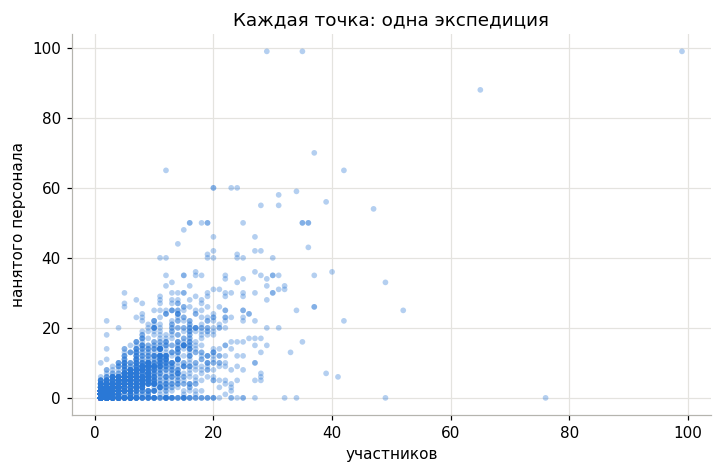

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(data["members"], data["hired_staff"], s=14, alpha=0.35, color=BLUE, edgecolor="none")
ax.set(xlabel="участников", ylabel="нанятого персонала", title="Каждая точка: одна экспедиция")
plt.show()

In [12]:
ratio = (data["hired_staff"] / data["members"]).groupby(data["year"] // 10 * 10)
pd.DataFrame({"экспедиций": ratio.size(), "медиана персонал/участник": ratio.median(),
              "доля без персонала": ratio.apply(lambda s: (s == 0).mean())})

,экспедиций,медиана персонал/участник,доля без персонала
year,,,
1920,3,2.333,0.000
1930,5,2.286,0.000
1940,1,2.000,0.000
1950,9,1.273,0.111
1960,12,1.227,0.417
1970,27,1.200,0.148
1980,141,0.364,0.319
1990,331,0.600,0.215
2000,745,0.800,0.184


Облако вытянуто вдоль прямой, но разброс растёт с размером экспедиции. Есть далёкие точки и полоса нулей, где никого не наняли. С 1980-х медианное отношение персонала к участникам выросло с 0.36 до 1.3. До 1980 года экспедиций всего 57, и на участника у них обычно приходилось больше одного человека персонала.

Модель:

$$\mathrm{hired\_staff}=\beta_0+\beta_1\,\mathrm{members}+\beta_2\,\mathrm{decade}+\beta_3\,\mathrm{spring}+\beta_4\,\mathrm{oxygen}+\beta_5\,\mathrm{nepal}+\varepsilon$$

`decade` равен (год − 2000)/10, `spring`, `oxygen` и `nepal` бинарные (весенний сезон, использование кислорода, непальская сторона).

In [13]:
features = ["members", "decade", "spring", "oxygen", "nepal"]
names = ["const"] + features
X = np.column_stack([np.ones(len(data)), data[features]]).astype(float)
y = data["hired_staff"].to_numpy(float)
n, p = X.shape
print("n =", n, " p =", p, " ранг X =", np.linalg.matrix_rank(X))

n = 2377  p = 6  ранг X = 6


## 1.2. Классические оценки: метод наименьших квадратов

Оценка минимизирует сумму квадратов остатков $r_i(\beta)=y_i-\beta'x_i$:

$$\hat\beta_{LS}=\arg\min_\beta\sum_{i=1}^n r_i(\beta)^2=(X'X)^{-1}X'y .$$

При нормальных ошибках с постоянной дисперсией это оценка максимального правдоподобия. Вклад наблюдения в уравнения равен $\psi(r)=r$ и ничем не ограничен, поэтому одно испорченное наблюдение может увести оценку сколь угодно далеко. Точка срыва равна 0.

In [14]:
XtX = X.T @ X
beta_ls = np.linalg.solve(XtX, X.T @ y)
pd.Series(beta_ls, index=names, name="МНК").to_frame().T

,const,members,decade,spring,oxygen,nepal
МНК,-4.796,0.895,0.158,2.370,1.296,2.968


In [15]:
r_ls = y - X @ beta_ls
s_ls = np.sqrt(r_ls @ r_ls / (n - p))
R2 = 1 - r_ls @ r_ls / np.sum((y - y.mean()) ** 2)
print(f"s = {s_ls:.3f}   R² = {R2:.3f}")

s = 6.779   R² = 0.522


In [16]:
se_ls = s_ls * np.sqrt(np.diag(np.linalg.inv(XtX)))
t_ls = beta_ls / se_ls
pd.DataFrame({"оценка": beta_ls, "SE": se_ls, "t": t_ls,
              "p-value": 2 * stats.t.sf(np.abs(t_ls), n - p)}, index=names)

,оценка,SE,t,p-value
const,-4.796,0.491,-9.771,0.000
members,0.895,0.019,46.909,0.000
decade,0.158,0.128,1.237,0.216
spring,2.370,0.475,4.984,0.000
oxygen,1.296,0.347,3.732,0.000
nepal,2.968,0.293,10.118,0.000


По МНК один участник добавляет 0.90 человека персонала, непальская сторона почти 3.0, весенний сезон 2.4, кислород 1.3. Коэффициент при `decade` равен 0.16, p-value 0.22: тренда по годам МНК не видит, хотя в таблице выше отношение растёт. Остальные коэффициенты значимы.

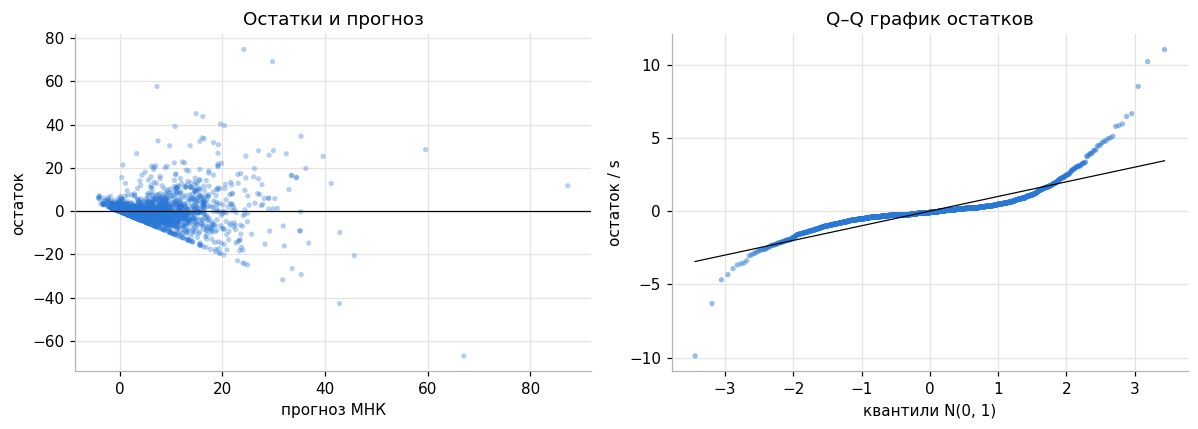

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(X @ beta_ls, r_ls, s=12, alpha=0.35, color=BLUE, edgecolor="none")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set(xlabel="прогноз МНК", ylabel="остаток", title="Остатки и прогноз")
q, v = stats.probplot(r_ls / s_ls, fit=False)
axes[1].scatter(q, v, s=12, alpha=0.5, color=BLUE, edgecolor="none")
axes[1].plot(q, q, color="black", lw=0.8)
axes[1].set(xlabel="квантили N(0, 1)", ylabel="остаток / s", title="Q–Q график остатков")
plt.tight_layout()
plt.show()

In [18]:
print(f"асимметрия {stats.skew(r_ls):.2f}, эксцесс {stats.kurtosis(r_ls):.2f}")
rs = stats.spearmanr(np.abs(r_ls), X @ beta_ls)
print(f"корреляция Спирмена |остаток| и прогноза: {rs.statistic:.3f}")

асимметрия 1.90, эксцесс 23.57
корреляция Спирмена |остаток| и прогноза: 0.478


Наблюдения с самой большой разбалансировкой, leverage (диагональ матрицы $H=X(X'X)^{-1}X'$):

In [19]:
leverage = np.sum(X @ np.linalg.inv(XtX) * X, axis=1)
view = data[["expedition_id", "year", "members", "hired_staff"]].assign(
    leverage=leverage, stand_resid=r_ls / s_ls)
print("среднее p/n =", round(p / n, 4))
view.sort_values("leverage", ascending=False).head(8)

среднее p/n = 0.0025


,expedition_id,year,members,hired_staff,leverage,stand_resid
96,EVER88101,1988,99,99,0.065,1.730
1136,EVER08101,2008,76,0,0.038,-9.883
386,EVER73101,1973,65,88,0.028,4.193
442,EVER21101,1921,9,21,0.027,2.452
443,EVER22101,1922,13,30,0.026,3.058
444,EVER24101,1924,11,40,0.025,4.793
446,EVER34101,1934,1,2,0.021,0.675
445,EVER33101,1933,16,50,0.021,5.778


И с самыми большими остатками:

In [20]:
view.loc[view["stand_resid"].abs().sort_values(ascending=False).index].head(8)

,expedition_id,year,members,hired_staff,leverage,stand_resid
460,EVER60102,1960,29,99,0.010,11.035
468,EVER75102,1975,35,99,0.009,10.208
1136,EVER08101,2008,76,0,0.038,-9.883
448,EVER36101,1936,12,65,0.019,8.511
407,EVER64101,1964,20,60,0.009,6.652
463,EVER66101,1966,20,60,0.007,6.457
1117,EVER07160,2007,49,0,0.015,-6.317
381,EVER75301,1975,23,60,0.006,5.951


Предпосылки МНК нарушены. Эксцесс остатков 24, хвосты на Q–Q графике намного тяжелее нормальных. Разброс растёт с прогнозом, корреляция Спирмена 0.48. Снизу облако остатков срезано наклонной прямой, потому что `hired_staff` не бывает отрицательным.

Среди точек с большим leverage 1988 год (99 участников и 99 нанятых), 2008 год (76 участников, ни одного нанятого), 1973 год (65 и 88) и экспедиции 1920–30-х. У многих из них большие и остатки.

## 1.3. MM-оценка

M-оценка регрессии минимизирует

$$L(\beta)=\sum_{i=1}^n\rho\!\left(\frac{r_i(\beta)}{\hat\sigma}\right).$$

С ограниченной $\rho$ грубые выбросы отбрасываются, но $L$ становится невыпуклой и ответ зависит от начальной точки. Ещё нужен масштаб $\hat\sigma$, который сами выбросы не испортили. MM-оценка (Yohai, 1987) строится так:

1. начальная оценка $\hat\beta_0$ с высокой точкой срыва (здесь S-оценка);
2. робастный масштаб $\hat\sigma$ остатков $r_i(\hat\beta_0)$;
3. M-оценка с более эффективной $\rho$, найденная итерациями от $\hat\beta_0$ при фиксированном $\hat\sigma$.

Точка срыва наследуется от первого шага, эффективность определяется третьим.

Точка срыва 0.5 достижима, только если $x_i$ в общем положении. Для любой регрессионно эквивариантной оценки она не больше $\frac1n\left[\frac{n-k^*-1}{2}\right]$, где $k^*$ равно наибольшему числу наблюдений на одной гиперплоскости $\theta'x=0$ (формулы 5.10–5.12). У нас на гиперплоскости $\text{const}-\text{spring}=0$ лежат все весенние экспедиции, 2085 из 2377, и граница равна $145/2377\approx0.061$. Срыв грозит свободному члену и `spring`: их по отдельности определяют 292 экспедиции остальных сезонов, и испортить достаточно половину из них.

### 1.3.1. Функция потерь бисквадрат

$$\rho_c(u)=\begin{cases}1-\left(1-(u/c)^2\right)^3,&|u|\le c\\1,&|u|>c\end{cases}\qquad
W_c(u)=\begin{cases}\left(1-(u/c)^2\right)^2,&|u|\le c\\0,&|u|>c\end{cases}$$

Здесь $W_c$ вес наблюдения во взвешенном МНК, а $\psi_c(u)=u\,W_c(u)$ с точностью до множителя. Для S-шага берётся $c_0=1.547$ (масштаб состоятелен при нормальных ошибках, точка срыва самого масштаба 0.5), для M-шага $c_1=3.44$ (эффективность 85 % при нормальных ошибках). Условие $\rho_{c_0}\ge\rho_{c_1}$ выполнено, так как $c_1>c_0$.

In [21]:
C0, C1 = 1.547, 3.44

def rho_bi(u, c):
    return np.where(np.abs(u) <= c, 1 - (1 - (u / c) ** 2) ** 3, 1.0)

def w_bi(u, c):
    return np.where(np.abs(u) <= c, (1 - (u / c) ** 2) ** 2, 0.0)

u = np.array([0, 1, 2, 3, 4])
pd.DataFrame({"u": u, "rho, c0": rho_bi(u, C0), "W, c0": w_bi(u, C0),
              "rho, c1": rho_bi(u, C1), "W, c1": w_bi(u, C1)})

,u,"rho, c0","W, c0","rho, c1","W, c1"
0,0,0.000,1.000,0.000,1.000
1,1,0.803,0.339,0.233,0.838
2,2,1.000,0.000,0.710,0.438
3,3,1.000,0.000,0.986,0.057
4,4,1.000,0.000,1.000,0.000


### 1.3.2. M-оценка масштаба

Масштаб $\hat\sigma$ определяется уравнением

$$\frac1n\sum_{i=1}^n\rho_{c_0}\!\left(\frac{r_i}{\hat\sigma}\right)=\delta,\qquad \delta=0.5,$$

и находится простыми итерациями $\sigma_{k+1}^2=\sigma_k^2\cdot\frac{1}{\delta n}\sum_i\rho_{c_0}(r_i/\sigma_k)$, начиная с MADN.

In [22]:
def m_scale(r, delta=0.5):
    s = np.median(np.abs(r)) / 0.6745
    for _ in range(200):
        s_new = s * np.sqrt(np.mean(rho_bi(r / s, C0)) / delta)
        if abs(s_new / s - 1) < 1e-10:
            break
        s = s_new
    return s_new

print("проверка на N(0, 1):", round(m_scale(np.random.default_rng(0).standard_normal(100_000)), 4))

проверка на N(0, 1): 1.0003


In [23]:
pd.Series({"стандартное отклонение": r_ls.std(), "MADN": np.median(np.abs(r_ls)) / 0.6745,
           "M-масштаб": m_scale(r_ls)}, name="остатки МНК").to_frame()

,остатки МНК
стандартное отклонение,6.771
MADN,2.953
M-масштаб,3.248


MADN и M-масштаб дают 3.0 и 3.2, стандартное отклонение 6.8. Выбросы завысили обычную оценку масштаба примерно в 2.2 раза.

### 1.3.3. Начальная S-оценка

S-оценка минимизирует робастный масштаб остатков: $\hat\beta_S=\arg\min_\beta\hat\sigma(r(\beta))$. Минимум ищется методом подвыборок:

1. $N$ раз выбираем случайные $p$ наблюдений и проводим через них гиперплоскость точно;
2. каждого кандидата улучшаем одним шагом взвешенного МНК и считаем масштаб остатков;
3. десять лучших доводим до сходимости, побеждает кандидат с наименьшим масштабом.

Чтобы с вероятностью 0.99 хотя бы одна подвыборка оказалась без выбросов, нужно $N\ge|\ln 0.01|/(1-\varepsilon)^p$.

In [24]:
for eps in (0.10, 0.25, 0.50):
    print(f"доля выбросов {eps:.2f}: N >= {np.ceil(abs(np.log(0.01)) / (1 - eps) ** p):.0f}")

доля выбросов 0.10: N >= 9
доля выбросов 0.25: N >= 26
доля выбросов 0.50: N >= 295


С запасом берём $N=500$. Подвыборки с вырожденной матрицей (например, когда попали только весенние экспедиции) пропускаются.

In [25]:
def wls(X, y, w):
    sw = np.sqrt(w)
    return np.linalg.lstsq(X * sw[:, None], y * sw, rcond=None)[0]

def s_candidates(X, y, N=500, seed=0):
    rng = np.random.default_rng(seed)
    n, p = X.shape
    betas, skipped = [], 0
    while len(betas) < N:
        J = rng.choice(n, p, replace=False)
        if np.linalg.matrix_rank(X[J]) < p:
            skipped += 1
            continue
        r = y - X @ np.linalg.solve(X[J], y[J])
        betas.append(wls(X, y, w_bi(r / m_scale(r), C0)))
    scales = np.array([m_scale(y - X @ b) for b in betas])
    order = np.argsort(scales)
    return np.array(betas)[order], scales[order], skipped

cand, cand_scale, skipped = s_candidates(X, y)
print("пропущено вырожденных подвыборок:", skipped)
print("масштаб кандидатов: min {:.3f}, медиана {:.3f}, max {:.3f}".format(
    cand_scale[0], np.median(cand_scale), cand_scale[-1]))

пропущено вырожденных подвыборок: 1055
масштаб кандидатов: min 2.552, медиана 3.844, max 12.144


In [26]:
pd.DataFrame(cand[:5], columns=names).assign(масштаб=cand_scale[:5])

,const,members,decade,spring,oxygen,nepal,масштаб
0,-3.595,0.939,0.354,2.238,0.906,0.706,2.552
1,-2.448,0.913,0.532,0.628,1.308,0.751,2.564
2,-1.435,0.496,0.301,0.551,1.098,0.875,2.582
3,-0.803,0.855,0.831,-0.983,0.789,0.247,2.583
4,-2.902,0.692,0.156,1.611,1.372,1.315,2.608


Доводим десять лучших кандидатов. На каждой итерации масштаб пересчитывается, затем делается шаг взвешенного МНК с весами $W_{c_0}(r_i/\hat\sigma)$.

In [27]:
def s_refine(X, y, b):
    for _ in range(500):
        r = y - X @ b
        b_new = wls(X, y, w_bi(r / m_scale(r), C0))
        done = np.max(np.abs(b_new - b)) < 1e-9
        b = b_new
        if done:
            break
    return b, m_scale(y - X @ b)

refined = [s_refine(X, y, b) for b in cand[:10]]
pd.DataFrame([b for b, _ in refined], columns=names).assign(масштаб=[s for _, s in refined])

,const,members,decade,spring,oxygen,nepal,масштаб
0,-2.531,0.910,0.517,1.015,0.835,0.455,2.473
1,-2.531,0.910,0.517,1.015,0.835,0.455,2.473
2,-1.903,0.683,0.451,0.597,1.172,0.610,2.471
3,-2.531,0.910,0.517,1.015,0.835,0.455,2.473
4,-1.903,0.683,0.451,0.597,1.172,0.610,2.471
5,-2.531,0.910,0.517,1.015,0.835,0.455,2.473
6,-1.903,0.683,0.451,0.597,1.172,0.610,2.471
7,-1.903,0.683,0.451,0.597,1.172,0.610,2.471
8,-1.903,0.683,0.451,0.597,1.172,0.610,2.471
9,-1.903,0.683,0.451,0.597,1.172,0.610,2.471


In [28]:
beta_s, sigma = min(refined, key=lambda t: t[1])
pd.DataFrame([beta_ls, beta_s], columns=names, index=["МНК", "S-оценка"]).assign(масштаб=[s_ls, sigma])

,const,members,decade,spring,oxygen,nepal,масштаб
МНК,-4.796,0.895,0.158,2.370,1.296,2.968,6.779
S-оценка,-1.903,0.683,0.451,0.597,1.172,0.610,2.471


Десять кандидатов разошлись на две точки. Шесть пришли в масштаб 2.471 с наклоном при `members` 0.68, четыре в 2.473 с наклоном 0.91. По масштабу минимумы почти равны (разница 0.1 %), а по коэффициентам разные, то есть сама S-оценка здесь неоднозначна. Берём меньший масштаб и ниже проверим, что меняется для MM. У МНК масштаб ошибки был 6.779.

### 1.3.4. M-шаг

При фиксированном $\hat\sigma$ решаем $\sum_i\psi_{c_1}(r_i/\hat\sigma)\,x_i=0$ итерациями взвешенного МНК от S-оценки. На каждой итерации $L(\beta)$ не растёт, поэтому условие $L(\hat\beta)\le L(\hat\beta_0)$ выполняется автоматически.

In [29]:
def m_step(X, y, b, sigma, c=C1):
    history = []
    for _ in range(1000):
        u = (y - X @ b) / sigma
        history.append([rho_bi(u, c).mean(), *b])
        b_new = wls(X, y, w_bi(u, c))
        done = np.max(np.abs(b_new - b)) < 1e-9
        b = b_new
        if done:
            break
    return b, history

beta_mm, history = m_step(X, y, beta_s, sigma)
history = pd.DataFrame(history, columns=["средняя потеря"] + names)
print("итераций:", len(history), " потеря не растёт:", bool((history["средняя потеря"].diff().dropna() <= 1e-12).all()))
history.iloc[[0, 1, 2, 5, 10, 20, len(history) - 1]].map("{:.5f}".format)

итераций: 87  потеря не растёт: True


,средняя потеря,const,members,decade,spring,oxygen,nepal
0,0.30122,-1.90307,0.68300,0.45124,0.59716,1.17173,0.60974
1,0.29716,-1.88061,0.68289,0.65216,0.29598,1.15726,1.00047
2,0.29643,-1.88700,0.68980,0.76867,0.15839,1.11689,1.11035
5,0.29612,-1.93814,0.70619,0.88752,0.08280,1.04993,1.14981
10,0.29607,-1.98665,0.71804,0.91608,0.09824,1.01936,1.14399
20,0.29607,-2.00848,0.72369,0.92465,0.10787,1.00715,1.13989
86,0.29607,-2.01170,0.72454,0.92587,0.10932,1.00535,1.13926


### 1.3.5. Устойчивость к выбору старта

Раз у S два почти равных минимума, запускаем M-шаг из обоих.

In [30]:
beta_s2 = max(refined, key=lambda t: t[1])[0]
beta_alt, _ = m_step(X, y, beta_s2, sigma)
pd.DataFrame([beta_s, beta_s2, beta_mm, beta_alt], columns=names,
             index=["S, лучший минимум", "S, второй минимум", "MM от лучшего", "MM от второго"])

,const,members,decade,spring,oxygen,nepal
"S, лучший минимум",-1.903,0.683,0.451,0.597,1.172,0.610
"S, второй минимум",-2.531,0.910,0.517,1.015,0.835,0.455
MM от лучшего,-2.012,0.725,0.926,0.109,1.005,1.139
MM от второго,-2.012,0.725,0.926,0.109,1.005,1.139


Из обоих стартов M-шаг приходит в одну точку: `members` 0.725, `decade` 0.926. Для MM неоднозначность S не имеет значения.

In [31]:
r_mm = y - X @ beta_mm
w_mm = w_bi(r_mm / sigma, C1)
k_star = int(X[:, names.index("spring")].sum())
print(f"весенних экспедиций {k_star} из {n}, точка срыва не выше {(n - k_star - 1) // 2} / {n} = {((n - k_star - 1) // 2) / n:.3f}")
print("вес 0:", (w_mm == 0).sum(), f"({(w_mm == 0).mean():.1%})   вес меньше 0.5: {(w_mm < 0.5).mean():.1%}   вес больше 0.9: {(w_mm > 0.9).mean():.1%}")

весенних экспедиций 2085 из 2377, точка срыва не выше 145 / 2377 = 0.061
вес 0: 258 (10.9%)   вес меньше 0.5: 21.2%   вес больше 0.9: 56.0%


### 1.3.6. Стандартные ошибки

Из разложения оценочного уравнения получается «сэндвич»

$$\widehat{\mathrm{Cov}}(\hat\beta)=\frac{\hat\sigma^2}{n}A^{-1}BA^{-1},\qquad
A=\frac1n\sum_i\psi'(u_i)\,x_ix_i',\quad B=\frac1n\sum_i\psi(u_i)^2\,x_ix_i',\quad u_i=r_i/\hat\sigma .$$

Формула годится для всех трёх оценок: у МНК $\psi(u)=u$, у GM к $\psi$ добавляется вес $W(d(x_i))$. Масштаб считается известным. Одинаковой дисперсии ошибок формула не требует, а на графике остатков разброс явно растёт с прогнозом.

In [32]:
def psi_bi(u, c):
    return u * w_bi(u, c)

def dpsi_bi(u, c):
    return np.where(np.abs(u) <= c, (1 - (u / c) ** 2) * (1 - 5 * (u / c) ** 2), 0.0)

def sandwich_se(X, psi, dpsi, sigma):
    n = len(X)
    A_inv = np.linalg.inv((X.T * dpsi) @ X / n)
    B = (X.T * psi ** 2) @ X / n
    return sigma * np.sqrt(np.diag(A_inv @ B @ A_inv) / n)

se_ls_sw = sandwich_se(X, r_ls / s_ls, np.ones(n), s_ls)
se_mm = sandwich_se(X, psi_bi(r_mm / sigma, C1), dpsi_bi(r_mm / sigma, C1), sigma)
pd.concat({"МНК": pd.DataFrame({"оценка": beta_ls, "SE обычная": se_ls, "SE сэндвич": se_ls_sw, "z": beta_ls / se_ls_sw}, index=names),
           "MM": pd.DataFrame({"оценка": beta_mm, "SE сэндвич": se_mm, "z": beta_mm / se_mm}, index=names)}, axis=1)

МНК                                  MM                  
        оценка SE обычная SE сэндвич      z оценка SE сэндвич      z
const   -4.796      0.491      0.576 -8.330 -2.012      0.325 -6.187
members  0.895      0.019      0.054 16.502  0.725      0.051 14.075
decade   0.158      0.128      0.311  0.509  0.926      0.116  7.978
spring   2.370      0.475      0.710  3.337  0.109      0.290  0.377
oxygen   1.296      0.347      0.324  3.995  1.005      0.172  5.829
nepal    2.968      0.293      0.289 10.276  1.139      0.117  9.708

Выводы у MM и МНК разные.

* `decade`: 0.16 у МНК ($z=0.5$ со сэндвичем) и 0.93 у MM ($z=8$).
* `spring`: 2.4 у МНК, у MM 0.11 при SE 0.29, то есть эффекта весны нет.
* `members`: 0.90 у МНК и 0.73 у MM.
* `nepal`: 3.0 у МНК и 1.1 у MM.

У `members`, `decade` и `spring` сэндвич-ошибки МНК в 1.5–2.8 раза больше обычных, у остальных совпадают. Нулевой вес в MM получили 258 экспедиций из 2377 (10.9 %).

## 1.4. Обобщённая M-оценка (GM)

Можно оставить монотонную $\psi$ и уменьшить вес наблюдений, далёких по $x$. Оценка Мэллоуза решает уравнение

$$\sum_{i=1}^n W(d(x_i))\,\psi\!\left(\frac{r_i(\beta)}{\hat\sigma}\right)x_i=0 ,$$

где $\psi$ Хьюбера: $\psi_k(u)=\max(-k,\min(k,u))$, $k=1.345$. Удалённость измеряем робастным расстоянием Махаланобиса $d(x)=\sqrt{(x-\hat\mu)'\hat\Sigma^{-1}(x-\hat\mu)}$. Центр $\hat\mu$ и ковариация $\hat\Sigma$ оцениваются по MCD: берутся те 75 % точек, у которых определитель ковариации наименьший. С весом $W(d)=\min(1,\,c/d)$, $c=\sqrt{\chi^2_{2;\,0.975}}$, произведение $W(d)\,d$ ограничено.

Расстояние считаем по `members` и `decade`. У бинарных признаков далёких значений нет.

In [33]:
Z = data[["members", "decade"]].to_numpy()
mcd = MinCovDet(support_fraction=0.75, random_state=0).fit(Z)
pd.DataFrame({"среднее": Z.mean(axis=0), "центр MCD": mcd.location_,
              "ст. откл.": Z.std(axis=0), "ст. откл. MCD": np.sqrt(np.diag(mcd.covariance_))},
             index=["members", "decade"])

,среднее,центр MCD,ст. откл.,ст. откл. MCD
members,7.485,4.822,7.628,3.694
decade,0.664,0.852,1.242,0.882


In [34]:
d = np.sqrt(mcd.mahalanobis(Z))
cut = np.sqrt(stats.chi2.ppf(0.975, 2))
W_x = np.minimum(1, cut / d)
print(f"порог {cut:.2f}, дальше порога {np.mean(d > cut):.1%} экспедиций, максимум d = {d.max():.1f}, наименьший вес {W_x.min():.3f}")
data[["expedition_id", "year", "members", "hired_staff"]].assign(d=d, W=W_x).sort_values("d", ascending=False).head(6)

порог 2.72, дальше порога 19.2% экспедиций, максимум d = 25.5, наименьший вес 0.107


,expedition_id,year,members,hired_staff,d,W
96,EVER88101,1988,99,99,25.493,0.107
1136,EVER08101,2008,76,0,19.344,0.140
386,EVER73101,1973,65,88,16.486,0.165
327,EVER80301,1980,52,25,12.937,0.210
385,EVER73301,1973,49,33,12.314,0.221
1117,EVER07160,2007,49,0,11.995,0.226


In [35]:
K = 1.345

def w_hub(u):
    return np.minimum(1, K / np.maximum(np.abs(u), 1e-12))

def gm_fit(X, y, W):
    b, history = wls(X, y, np.ones(len(y))), []
    for _ in range(500):
        r = y - X @ b
        s = m_scale(r)
        history.append([s, *b])
        b_new = wls(X, y, W * w_hub(r / s))
        done = np.max(np.abs(b_new - b)) < 1e-9
        b = b_new
        if done:
            break
    return b, s, history

beta_gm, sigma_gm, history = gm_fit(X, y, W_x)
history = pd.DataFrame(history, columns=["масштаб"] + names)
history.iloc[[0, 1, 2, 5, 10, len(history) - 1]]

,масштаб,const,members,decade,spring,oxygen,nepal
0,3.248,-4.796,0.895,0.158,2.370,1.296,2.968
1,2.807,-3.170,0.861,0.883,0.562,1.123,1.912
2,2.764,-2.820,0.839,1.033,0.226,1.107,1.703
5,2.760,-2.693,0.820,1.080,0.118,1.120,1.661
10,2.760,-2.687,0.818,1.081,0.115,1.122,1.661
23,2.760,-2.687,0.818,1.081,0.115,1.122,1.661


Для сравнения та же оценка Хьюбера без весов по $x$ (все $W=1$):

In [36]:
beta_hub, sigma_hub, _ = gm_fit(X, y, np.ones(n))
u_gm = (y - X @ beta_gm) / sigma_gm
se_gm = sandwich_se(X, W_x * np.clip(u_gm, -K, K), W_x * (np.abs(u_gm) <= K), sigma_gm)
pd.DataFrame([beta_ls, beta_hub, beta_gm, beta_mm], columns=names,
             index=["МНК", "Хьюбер, W = 1", "GM (Мэллоуз)", "MM"]).assign(масштаб=[s_ls, sigma_hub, sigma_gm, sigma])

,const,members,decade,spring,oxygen,nepal,масштаб
МНК,-4.796,0.895,0.158,2.370,1.296,2.968,6.779
"Хьюбер, W = 1",-3.128,0.844,0.996,0.579,0.998,1.827,2.784
GM (Мэллоуз),-2.687,0.818,1.081,0.115,1.122,1.661,2.760
MM,-2.012,0.725,0.926,0.109,1.005,1.139,2.471


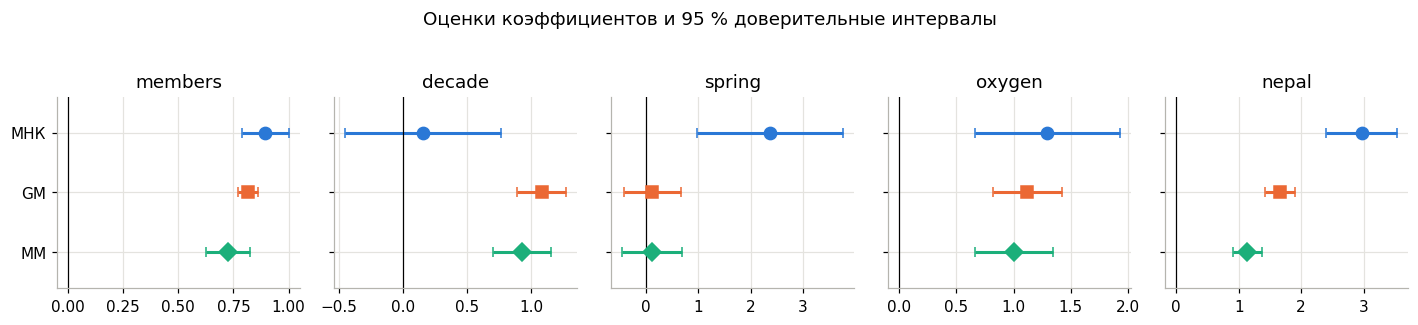

In [37]:
fits = {"МНК": (beta_ls, se_ls_sw, BLUE, "o"), "GM": (beta_gm, se_gm, ORANGE, "s"), "MM": (beta_mm, se_mm, AQUA, "D")}
fig, axes = plt.subplots(1, 5, figsize=(13, 2.8))
for j, ax in enumerate(axes, start=1):
    for pos, (label, (b, se, color, marker)) in enumerate(fits.items()):
        ax.errorbar(b[j], -pos, xerr=1.96 * se[j], color=color, marker=marker, ms=8, lw=2, capsize=3)
    ax.axvline(0, color="black", lw=0.8)
    ax.set(title=names[j], yticks=[0, -1, -2], yticklabels=list(fits) if j == 1 else [], ylim=(-2.6, 0.6))
fig.suptitle("Оценки коэффициентов и 95 % доверительные интервалы", y=1.04)
plt.tight_layout()
plt.show()

GM и MM согласны по знакам: тренд 1.08 и 0.93 за десятилетие, весна около нуля. По величине они расходятся сильнее: `members` 0.82 и 0.73, `nepal` 1.66 и 1.14. У GM вес плохой точки мал, но нулём не становится, и масштаб у неё 2.76, а у MM 2.47.

Хьюбер без весов по $x$ даёт весну 0.58, с весами 0.12: на него давили далёкие по $x$ экспедиции. GM считается проще, подвыборки не нужны. В общем положении её точка срыва меньше 0.5 и падает с ростом $p$, а у MM она 0.5. На наших данных из-за `spring` обе ограничены сверху числом 0.061 (раздел 1.3).

## 1.5. Доверительные интервалы и тесты

### 1.5.1. Какая ковариационная матрица

В классической асимптотике $\widehat{\mathrm{Cov}}(\hat\beta)=\hat v\,(X'X)^{-1}$, $\hat v=\hat\sigma^2\,\frac{\mathrm{ave}\,\psi^2}{(\mathrm{ave}\,\psi')^2}\frac n{n-p}$. Матрицу $X'X$ портят далёкие $x$, поэтому в книге (5.39) вместо неё берут $\tilde V_x=\sum w_ix_ix_i'/\sum w_i$ с весами $w_i=W(r_i/\hat\sigma)$. Формула всё ещё предполагает одинаковую и независимую дисперсию ошибок. Здесь разброс растёт с прогнозом, поэтому мы пользуемся сэндвичем.

Независимость тоже нарушена. Экспедиции одного года связаны общими событиями, например лавиной 2014 года и землетрясением 2015-го. Вклады $\psi_ix_i$ внутри года складываем и считаем матрицу по годам:

$$\widehat{\mathrm{Cov}}=\frac{\hat\sigma^2}n A^{-1}B_{\mathrm{cl}}A^{-1},\qquad B_{\mathrm{cl}}=\frac1n\sum_{g}\Bigl(\sum_{i\in g}\psi_ix_i\Bigr)\Bigl(\sum_{i\in g}\psi_ix_i\Bigr)'\cdot\frac{G}{G-1}.$$

Независимая проверка сэндвича: бутстрап, 300 повторов парами. S-оценка на каждом повторе уточняется от найденной, без новых подвыборок, затем M-шаг.

In [38]:
u_mm = r_mm / sigma
v_hat = sigma ** 2 * np.mean(psi_bi(u_mm, C1) ** 2) / np.mean(dpsi_bi(u_mm, C1)) ** 2 * n / (n - p)
V_tilde = (X.T * w_mm) @ X / w_mm.sum()
se_539 = np.sqrt(np.diag(v_hat / n * np.linalg.inv(V_tilde)))

def cluster_se(X, psi, dpsi, sigma, groups):
    A_inv = np.linalg.inv((X.T * dpsi) @ X / len(X))
    S = pd.DataFrame(psi[:, None] * X).groupby(groups).sum().to_numpy()
    B = S.T @ S / len(X) * len(S) / (len(S) - 1)
    return sigma * np.sqrt(np.diag(A_inv @ B @ A_inv) / len(X))

years = data["year"].to_numpy()
psi_u, dpsi_u = psi_bi(u_mm, C1), dpsi_bi(u_mm, C1)
se_cl = cluster_se(X, psi_u, dpsi_u, sigma, years)
pd.DataFrame({"(5.39)": se_539, "сэндвич": se_mm, "кластеры по годам": se_cl, "кластеры / сэндвич": se_cl / se_mm}, index=names)

,(5.39),сэндвич,кластеры по годам,кластеры / сэндвич
const,0.196,0.325,0.546,1.679
members,0.011,0.051,0.108,2.101
decade,0.064,0.116,0.205,1.762
spring,0.198,0.290,0.337,1.160
oxygen,0.134,0.172,0.226,1.309
nepal,0.112,0.117,0.213,1.813


In [39]:
rng = np.random.default_rng(1)
boot = []
for _ in range(300):
    i = rng.integers(0, n, n)
    b_i, s_i = s_refine(X[i], y[i], beta_s)
    boot.append(m_step(X[i], y[i], b_i, s_i)[0])
se_boot = np.std(boot, axis=0)
pd.DataFrame({"сэндвич": se_mm, "бутстрап": se_boot}, index=names).T

,const,members,decade,spring,oxygen,nepal
сэндвич,0.325,0.051,0.116,0.290,0.172,0.117
бутстрап,0.311,0.051,0.111,0.289,0.179,0.122


In [40]:
def interval(b, se):
    return [f"{x:.2f} … {z:.2f}" for x, z in zip(b - 1.96 * se, b + 1.96 * se)]

pd.DataFrame({"МНК, обычный": interval(beta_ls, se_ls), "МНК, сэндвич": interval(beta_ls, se_ls_sw),
              "GM": interval(beta_gm, se_gm), "MM, (5.39)": interval(beta_mm, se_539),
              "MM, сэндвич": interval(beta_mm, se_mm), "MM, кластеры": interval(beta_mm, se_cl)}, index=names).T

,const,members,decade,spring,oxygen,nepal
"МНК, обычный",-5.76 … -3.83,0.86 … 0.93,-0.09 … 0.41,1.44 … 3.30,0.62 … 1.98,2.39 … 3.54
"МНК, сэндвич",-5.92 … -3.67,0.79 … 1.00,-0.45 … 0.77,0.98 … 3.76,0.66 … 1.93,2.40 … 3.53
GM,-3.21 … -2.17,0.77 … 0.86,0.89 … 1.27,-0.43 … 0.66,0.82 … 1.43,1.42 … 1.91
"MM, (5.39)",-2.39 … -1.63,0.70 … 0.75,0.80 … 1.05,-0.28 … 0.50,0.74 … 1.27,0.92 … 1.36
"MM, сэндвич",-2.65 … -1.37,0.62 … 0.83,0.70 … 1.15,-0.46 … 0.68,0.67 … 1.34,0.91 … 1.37
"MM, кластеры",-3.08 … -0.94,0.51 … 0.94,0.53 … 1.33,-0.55 … 0.77,0.56 … 1.45,0.72 … 1.56


Бутстрап даёт те же ошибки, что сэндвич: 0.051 и 0.051 у `members`, 0.111 и 0.116 у `decade`. Формула (5.39) занижает: 0.011 и 0.064. Кластерные ошибки ещё в 1.2–2.1 раза больше сэндвича: у `members` 0.108, у `decade` 0.205. Интервал для `decade` в MM: 0.70…1.15 по сэндвичу, 0.53…1.33 по кластерам, ноль не входит ни в один. Для `spring` ноль внутри обоих.

### 1.5.2. Тесты

Тест Вальда сравнивает оценку с её ошибкой: $T_W=(\hat\beta_j/\mathrm{SE}_j)^2$ и сравнивается с $\chi^2_1$. Он опирается на ковариацию, которую портят далёкие $x$.

Аналог теста отношения правдоподобия (4.7.2) берёт разность сумм $\rho$ в модели с $\beta_j=0$ и без ограничения:

$$T_L=\sum_i\rho\!\left(\frac{r_i(\hat\beta_R)}{\hat\sigma}\right)-\sum_i\rho\!\left(\frac{r_i(\hat\beta)}{\hat\sigma}\right),\qquad 2\hat\xi\,T_L\to\chi^2_1,\quad \hat\xi=\frac{\mathrm{ave}\,\psi'}{\mathrm{ave}\,\psi^2}.$$

Ограниченная $\rho$ не даёт выбросам перетянуть разность. Множитель 2 нужен: при $\rho=u^2/2$ без него статистика не превращается в обычный F-тест.

In [41]:
def lrtt(j):
    rest = [k for k in range(p) if k != j]
    b_r, _ = m_step(X[:, rest], y, beta_mm[rest], sigma)
    u_r = (y - X[:, rest] @ b_r) / sigma
    t = norm_bi * (rho_bi(u_r, C1).sum() - rho_bi(u_mm, C1).sum())
    return 2 * t * np.mean(dpsi_bi(u_mm, C1)) / np.mean(psi_bi(u_mm, C1) ** 2)

norm_bi = C1 ** 2 / 6
wald = (beta_mm / se_mm) ** 2
wald_cl = (beta_mm / se_cl) ** 2
stat = np.array([lrtt(j) for j in range(1, p)])
pd.concat({"LRTT": pd.DataFrame({"статистика": stat, "p": stats.chi2.sf(stat, 1)}, index=names[1:]),
           "Вальд, сэндвич": pd.DataFrame({"статистика": wald[1:], "p": stats.chi2.sf(wald[1:], 1)}, index=names[1:]),
           "Вальд, кластеры": pd.DataFrame({"статистика": wald_cl[1:], "p": stats.chi2.sf(wald_cl[1:], 1)}, index=names[1:])}, axis=1).map("{:.4g}".format)

LRTT             Вальд, сэндвич            Вальд, кластеры  \
        статистика           p     статистика          p      статистика   
members       1271  1.943e-278          198.1  5.384e-45           44.86   
decade       139.9   2.756e-32          63.65  1.488e-15           20.49   
spring      0.2503      0.6169          0.142     0.7063          0.1054   
oxygen       51.96   5.668e-13          33.97   5.59e-09           19.84   
nepal        101.4   7.371e-24          94.25  2.788e-22           28.68   

                    
                 p  
members  2.111e-11  
decade   5.979e-06  
spring      0.7454  
oxygen   8.426e-06  
nepal    8.554e-08

Весна не нужна: LRTT 0.25 ($p=0.62$), Вальд 0.14 и 0.11. Для `decade` LRTT 140, Вальд 64 и с кластерами 20, во всех случаях $p<10^{-5}$. `members`, `oxygen` и `nepal` значимы при любой ошибке, с кластерами статистика в 1.7–4.4 раза меньше. LRTT предполагает одинаковую дисперсию, поэтому для него числа приблизительны.

## 1.6. Сравнение функций потерь

| | МНК | Хьюбер (GM) | бисквадрат (MM) |
|---|---|---|---|
| $\rho(u)$ | $u^2/2$ | $u^2/2$ при $\lvert u\rvert\le k$, иначе $k\lvert u\rvert-k^2/2$ | $1-(1-(u/c)^2)^3$ при $\lvert u\rvert\le c$, иначе $1$ |
| рост на бесконечности | квадратичный | линейный | ограничена |
| $\psi(u)$ | не ограничена | ограничена, монотонна | возвращается к нулю |
| вес выброса | $1$ | $k/\lvert u\rvert$ | $0$ |
| выпуклость | да | да | нет |

### 1.6.1. Форма функций

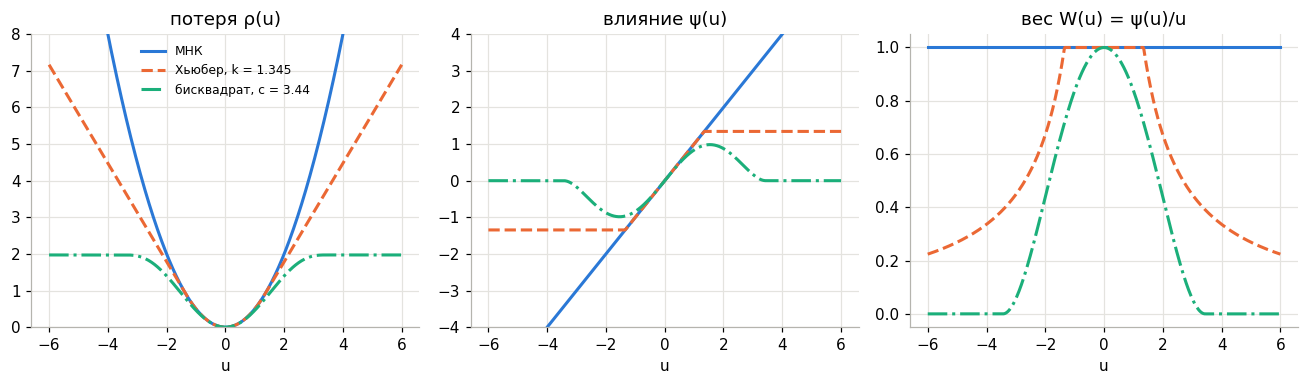

In [42]:
def rho_hub(u):
    return np.where(np.abs(u) <= K, u ** 2 / 2, K * np.abs(u) - K ** 2 / 2)

grid = np.linspace(-6, 6, 600)
norm_bi = C1 ** 2 / 6
curves = [("МНК", BLUE, "-", grid ** 2 / 2, grid, np.ones_like(grid)),
          ("Хьюбер, k = 1.345", ORANGE, "--", rho_hub(grid), np.clip(grid, -K, K), w_hub(grid)),
          ("бисквадрат, c = 3.44", AQUA, "-.", norm_bi * rho_bi(grid, C1), psi_bi(grid, C1), w_bi(grid, C1))]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for label, color, ls, rho_v, psi_v, w_v in curves:
    for ax, v in zip(axes, (rho_v, psi_v, w_v)):
        ax.plot(grid, v, color=color, ls=ls, lw=2, label=label)
axes[0].set(title="потеря ρ(u)", ylim=(0, 8), xlabel="u")
axes[1].set(title="влияние ψ(u)", ylim=(-4, 4), xlabel="u")
axes[2].set(title="вес W(u) = ψ(u)/u", xlabel="u")
axes[0].legend(loc="upper center", fontsize=8)
plt.tight_layout()
plt.show()

Бисквадрат умножен на $c^2/6$, чтобы около нуля все три кривые совпадали с $u^2/2$. Сколько экспедиций попадает в каждую область:

In [43]:
u_mm = r_mm / sigma
zones = pd.cut(np.abs(u_mm), [0, K, C1, np.inf], include_lowest=True,
               labels=["|u| ≤ 1.345: потери почти одинаковы", "1.345–3.44: Хьюбер и бисквадрат гасят", "> 3.44: бисквадрат постоянен"])
pd.DataFrame({"наблюдений": pd.Series(zones).value_counts(sort=False),
              "доля": pd.Series(zones).value_counts(sort=False, normalize=True)})

,наблюдений,доля
|u| ≤ 1.345: потери почти одинаковы,1693,0.712
1.345–3.44: Хьюбер и бисквадрат гасят,426,0.179
> 3.44: бисквадрат постоянен,258,0.109


### 1.6.2. Каждая оценка под каждой потерей

Средняя потеря при одном и том же масштабе $\hat\sigma$ S-оценки. У бисквадрата множитель $c^2/6$ оставлен.

In [44]:
def losses(b):
    u = (y - X @ b) / sigma
    return [np.mean(u ** 2 / 2), np.mean(rho_hub(u)), np.mean(norm_bi * rho_bi(u, C1))]

cross = pd.DataFrame([losses(b) for b in (beta_ls, beta_gm, beta_mm)], index=["МНК", "GM", "MM"],
                     columns=["квадратичная", "Хьюбера", "бисквадрат"])
cross

,квадратичная,Хьюбера,бисквадрат
МНК,3.755,1.411,0.658
GM,3.953,1.353,0.594
MM,4.175,1.383,0.584


In [45]:
((cross / cross.min() - 1) * 100).rename(columns=lambda c: c + ", проигрыш %").map("{:.1f}".format)

,"квадратичная, проигрыш %","Хьюбера, проигрыш %","бисквадрат, проигрыш %"
МНК,0.0,4.3,12.7
GM,5.3,0.0,1.7
MM,11.2,2.2,0.0


У МНК наименьшая квадратичная потеря, у MM наименьший бисквадрат, так и должно быть. GM минимизирует взвешенную потерю Хьюбера, а без весов минимум достигается при $W=1$, но из трёх строк она лучшая. МНК проигрывает по бисквадрату 12.7 %, MM по квадратичной 11.2 %. GM и MM отличаются по бисквадрату на 1.7 %.

### 1.6.3. Откуда берётся потеря

Экспедиции упорядочены по величине остатка, самые далёкие идут первыми. По вертикали накопленная доля общей потери.

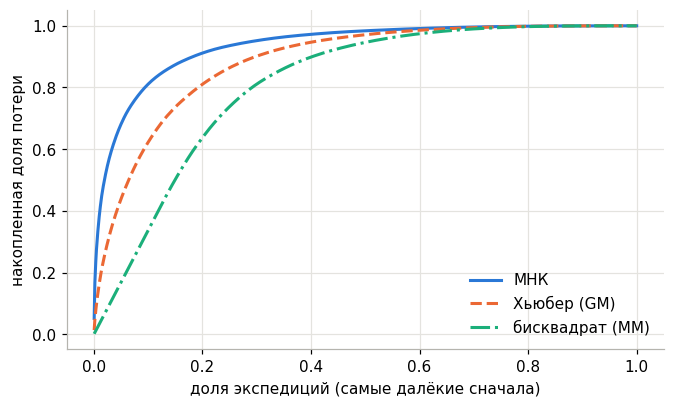

In [46]:
parts = {"МНК": (BLUE, "-", (r_ls / sigma) ** 2 / 2),
         "Хьюбер (GM)": (ORANGE, "--", rho_hub((y - X @ beta_gm) / sigma)),
         "бисквадрат (MM)": (AQUA, "-.", rho_bi(u_mm, C1))}
fig, ax = plt.subplots(figsize=(7, 4))
share = np.arange(1, n + 1) / n
for label, (color, ls, v) in parts.items():
    ax.plot(share, np.cumsum(np.sort(v)[::-1]) / v.sum(), color=color, ls=ls, lw=2, label=label)
ax.set(xlabel="доля экспедиций (самые далёкие сначала)", ylabel="накопленная доля потери")
ax.legend(loc="lower right")
plt.show()

In [47]:
pd.DataFrame({label: [np.sort(v)[::-1][: int(q * n)].sum() / v.sum() for q in (0.01, 0.05, 0.10)]
              for label, (_, _, v) in parts.items()}, index=["1 % самых далёких", "5 %", "10 %"])

,МНК,Хьюбер (GM),бисквадрат (MM)
1 % самых далёких,0.381,0.163,0.033
5 %,0.680,0.437,0.168
10 %,0.811,0.622,0.337


У МНК 1 % экспедиций (23 штуки) даёт 38 % всей потери, 10 % дают 81 %. У бисквадрата это 3 % и 34 %. Прямой участок в начале его кривой соответствует наблюдениям с одинаковой максимальной потерей 1. Получается, что оценку МНК во многом определяют два десятка необычных экспедиций.

### 1.6.4. Профили потерь по одному коэффициенту

Коэффициент $\beta_j$ фиксируем на сетке, остальные подбираем заново и получаем профиль $\min_{\beta_{-j}}L(\beta)$. Его минимум стоит ровно в оценке. Каждая кривая поделена на свой минимум, чтобы их можно было сравнивать.

In [48]:
def profile(j, values):
    rest = [k for k in range(p) if k != j]
    out = []
    for val in values:
        yj = y - X[:, j] * val
        b_q = wls(X[:, rest], yj, np.ones(n))
        b_b, _ = m_step(X[:, rest], yj, beta_mm[rest], sigma)
        out.append([np.mean(((yj - X[:, rest] @ b_q) / sigma) ** 2) / 2,
                    np.mean(rho_bi((yj - X[:, rest] @ b_b) / sigma, C1))])
    return np.array(out)

prof_grids = {"decade": np.linspace(-2.5, 3, 56), "members": np.linspace(0.2, 1.2, 51), "spring": np.linspace(-3, 5, 41)}
prof = {name: profile(names.index(name), g) for name, g in prof_grids.items()}
pd.DataFrame({name: [g[prof[name][:, 0].argmin()], g[prof[name][:, 1].argmin()]] for name, g in prof_grids.items()},
             index=["минимум квадратичной потери", "минимум бисквадрата"])

,decade,members,spring
минимум квадратичной потери,0.200,0.900,2.400
минимум бисквадрата,0.900,0.720,0.200


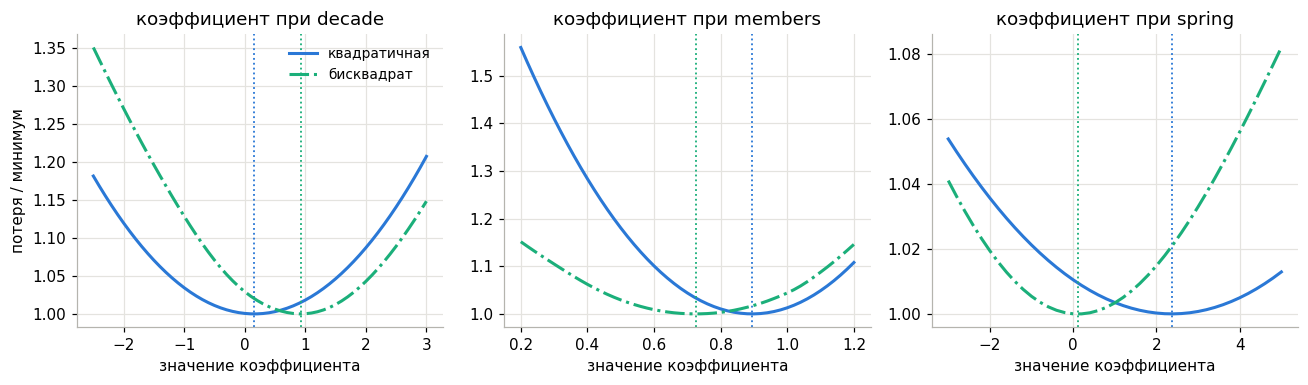

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, g) in zip(axes, prof_grids.items()):
    j = names.index(name)
    for col, (label, color, ls, b) in enumerate([("квадратичная", BLUE, "-", beta_ls), ("бисквадрат", AQUA, "-.", beta_mm)]):
        ax.plot(g, prof[name][:, col] / prof[name][:, col].min(), color=color, ls=ls, lw=2, label=label)
        ax.axvline(b[j], color=color, ls=":", lw=1.2)
    ax.set(title=f"коэффициент при {name}", xlabel="значение коэффициента", ylabel="потеря / минимум" if name == "decade" else "")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

### 1.6.5. Поверхность потерь в модели с двумя параметрами

Целиком поверхность рисуется только для двух параметров, поэтому здесь упрощённая модель $\mathrm{hired\_staff}=\beta_0+\beta_1\,\mathrm{members}$.

In [50]:
X2 = X[:, :2]
beta2_ls = wls(X2, y, np.ones(n))
b0 = s_candidates(X2, y)[0][0]
beta2_s, sigma2 = s_refine(X2, y, b0)
beta2_mm, _ = m_step(X2, y, beta2_s, sigma2)
pd.DataFrame([beta2_ls, beta2_mm], columns=["beta0", "beta1"], index=["МНК", "MM"])

,beta0,beta1
МНК,0.200,0.892
MM,0.347,0.716


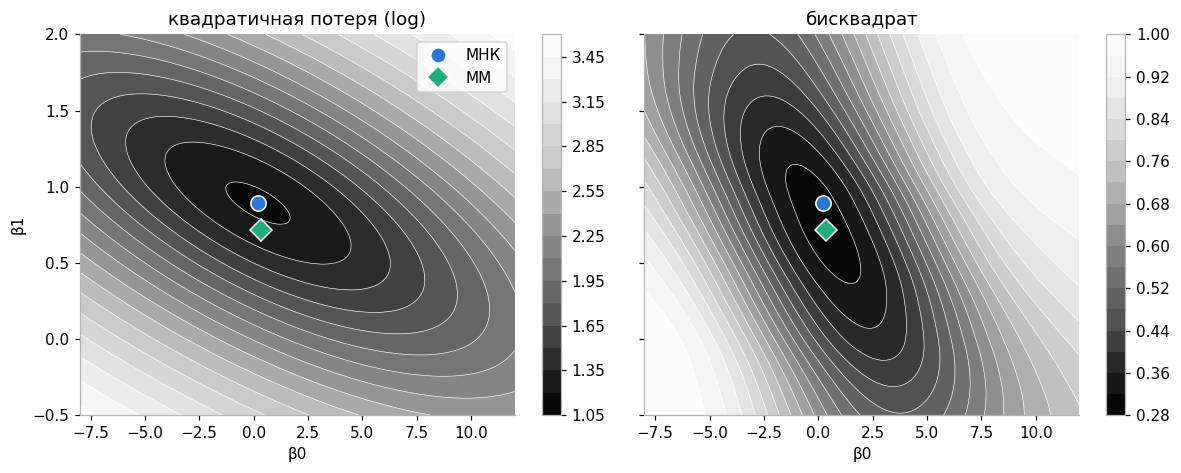

In [51]:
B0, B1 = np.meshgrid(np.linspace(-8, 12, 120), np.linspace(-0.5, 2.0, 120))
R = (y[:, None] - B0.ravel() - np.outer(X2[:, 1], B1.ravel())) / sigma2
surf = {"квадратичная потеря (log)": np.log(np.mean(R ** 2 / 2, axis=0)).reshape(B0.shape),
        "бисквадрат": np.mean(rho_bi(R, C1), axis=0).reshape(B0.shape)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, (title, Z_) in zip(axes, surf.items()):
    cs = ax.contourf(B0, B1, Z_, 22, cmap="Greys_r")
    ax.contour(B0, B1, Z_, 22, colors="white", linewidths=0.4)
    ax.plot(*beta2_ls, "o", color=BLUE, ms=10, mec="white", label="МНК")
    ax.plot(*beta2_mm, "D", color=AQUA, ms=10, mec="white", label="MM")
    ax.set(title=title, xlabel="β0")
    ax.grid(False)
    fig.colorbar(cs, ax=ax)
axes[0].set_ylabel("β1")
axes[0].legend(loc="upper right", labelcolor="black", frameon=True)
plt.tight_layout()
plt.show()

### 1.6.6. Насколько визуализация разумна

В полной модели шесть параметров, и целиком поверхность не нарисовать. Профиль показывает её вдоль одного коэффициента, а остальные подбирает, поэтому минимум профиля совпадает с оценкой. Если заморозить остальные коэффициенты, минимум сместится.

У `decade` минимум квадратичной потери около 0.2, бисквадрата около 0.9. У `spring` это 2.4 и 0.2, причём квадратичный профиль пологий: при нулевом коэффициенте потеря больше минимальной примерно на 1 %.

Контуры для двух параметров полные. У квадратичной потери это эллипсы. Бисквадрат вдали от минимума выходит на плато около 1, градиент там почти нулевой, и итерации, начатые оттуда, застрянут. Поэтому MM нужна хорошая начальная точка. Сама модель при этом упрощённая, её наклоны (0.89 у МНК и 0.72 у MM) полную не заменяют.

## 1.7. Природа выбросов (опционально)

По вертикали робастный остаток $u_i=r_i/\hat\sigma$, по горизонтали расстояние $d(x_i)$. Горизонтальные линии на $\pm 3.44$ (дальше вес в MM нулевой), вертикальная на пороге $d$.

In [52]:
out = np.abs(u_mm) > C1
far = d > cut
groups = [("обычные", ~out & ~far, GREY), ("хорошая разбалансировка", ~out & far, BLUE),
          ("вертикальные выбросы", out & ~far, ORANGE), ("плохая разбалансировка", out & far, AQUA)]
pd.DataFrame({"наблюдений": [m.sum() for _, m, _ in groups], "доля": [m.mean() for _, m, _ in groups]},
             index=[g[0] for g in groups])

,наблюдений,доля
обычные,1857,0.781
хорошая разбалансировка,262,0.110
вертикальные выбросы,64,0.027
плохая разбалансировка,194,0.082


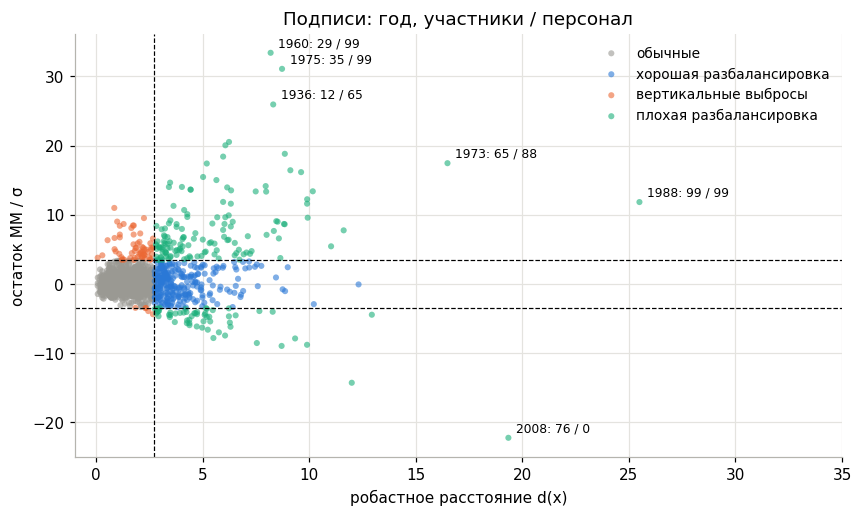

In [53]:
fig, ax = plt.subplots(figsize=(9, 5))
for label, mask, color in groups:
    ax.scatter(d[mask], u_mm[mask], s=16, alpha=0.6, color=color, edgecolor="none", label=label)
for h in (C1, -C1):
    ax.axhline(h, color="black", lw=0.8, ls="--")
ax.axvline(cut, color="black", lw=0.8, ls="--")
bad = np.where(out & far)[0]
top = set(bad[np.argsort(-np.abs(u_mm[bad]))[:3]]) | set(bad[np.argsort(-d[bad])[:3]])
for i in top:
    row = data.iloc[i]
    ax.annotate(f"{row['year']}: {row['members']} / {row['hired_staff']}", (d[i], u_mm[i]),
                xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.set(xlabel="робастное расстояние d(x)", ylabel="остаток MM / σ", title="Подписи: год, участники / персонал")
ax.legend(loc="upper right", fontsize=9)
ax.set_xlim(-1, 35)
plt.show()

In [54]:
flag = data.assign(выброс=out, dec10=data["year"] // 10 * 10)
pd.DataFrame({"экспедиций": flag.groupby("dec10").size(),
              "выбросов вверх": flag[out & (u_mm > 0)].groupby("dec10").size(),
              "выбросов вниз": flag[out & (u_mm < 0)].groupby("dec10").size(),
              "доля выбросов": flag.groupby("dec10")["выброс"].mean()}).fillna(0)

,экспедиций,выбросов вверх,выбросов вниз,доля выбросов
dec10,,,,
1920,3,3.000,0.000,1.000
1930,5,5.000,0.000,1.000
1940,1,0.000,0.000,0.000
1950,9,6.000,0.000,0.667
1960,12,6.000,1.000,0.583
1970,27,16.000,1.000,0.630
1980,141,14.000,16.000,0.213
1990,331,17.000,22.000,0.118
2000,745,26.000,10.000,0.048


Размер экспедиций среди выбросов и среди остальных:

In [55]:
flag.groupby("выброс")[["members", "hired_staff"]].median().assign(
    доля_без_персонала=flag.groupby("выброс")["hired_staff"].apply(lambda s: (s == 0).mean()))

,members,hired_staff,доля_без_персонала
выброс,,,
False,4.000,3.000,0.173
True,16.000,23.000,0.155


Самые большие команды, которые не нанимали никого:

In [56]:
data.assign(u=u_mm)[data["hired_staff"] == 0].sort_values("u").head(6)[
    ["expedition_id", "year", "nation", "members", "hired_staff", "no_hired", "u"]]

,expedition_id,year,nation,members,hired_staff,no_hired,u
1136,EVER08101,2008,China,76,0,False,-22.223
1117,EVER07160,2007,China,49,0,False,-14.268
402,EVER70101,1970,Japan,34,0,False,-8.944
51,EVER88305,1988,USA,32,0,True,-8.527
1428,EVER10116,2010,Nepal,25,0,True,-7.804
354,EVER97108,1997,Kazakhstan,27,0,True,-7.442


Записи, где число людей равно ровно 99:

In [57]:
data.assign(u=u_mm)[(data["members"] == 99) | (data["hired_staff"] == 99)][
    ["expedition_id", "year", "members", "hired_staff", "u"]]

,expedition_id,year,members,hired_staff,u
96,EVER88101,1988,99,99,11.850
460,EVER60102,1960,29,99,33.426
468,EVER75102,1975,35,99,31.104


Справочник просит читать ноль в `TOTHIRED` вместе с `NOHIRED`. Из 406 нулей 347 подтверждены отметкой, 59 нет. В этих 59 записях есть 7 погибших нанятых при нуле нанятых: 1970 год (6 погибших) и 1969 год (1). В этих двух записях число нанятых просто не внесено. Среди 63 выбросов вниз нулей 40, из них 11 без отметки.

In [58]:
zero = data[data["hired_staff"] == 0]
pd.DataFrame({"экспедиций": zero.groupby("no_hired").size(), "медиана участников": zero.groupby("no_hired")["members"].median(),
              "погибло нанятых": zero.groupby("no_hired")["hired_staff_deaths"].sum()})

,экспедиций,медиана участников,погибло нанятых
no_hired,,,
False,59,4.000,7
True,347,2.000,0


In [59]:
zero[(~zero["no_hired"]) & (zero["hired_staff_deaths"] > 0)][["expedition_id", "year", "nation", "members", "hired_staff", "hired_staff_deaths", "no_hired"]]

,expedition_id,year,nation,members,hired_staff,hired_staff_deaths,no_hired
402,EVER70101,1970,Japan,34,0,6,False
404,EVER69302,1969,Japan,16,0,1,False


In [60]:
down = data.assign(u=u_mm)[out & (u_mm < 0)]
pd.crosstab(down["hired_staff"] == 0, down["no_hired"]).rename_axis("персонал = 0")

no_hired,False,True
персонал = 0,,
False,23,0
True,11,29


Проверка на устойчивость: убираем 59 строк с неподтверждённым нулём.

In [61]:
def mm_fit(X, y, N=500):
    b, s = min((s_refine(X, y, c) for c in s_candidates(X, y, N)[0][:10]), key=lambda t: t[1])
    return m_step(X, y, b, s)[0], s

ok = ~((data["hired_staff"] == 0) & ~data["no_hired"]).to_numpy()
ls_clean = wls(X[ok], y[ok], np.ones(ok.sum()))
mm_clean, _ = mm_fit(X[ok], y[ok])
change = pd.DataFrame([beta_ls, ls_clean, beta_mm, mm_clean], columns=names,
                      index=["МНК, все строки", "МНК, без 59", "MM, все строки", "MM, без 59"])
print("убрано строк:", (~ok).sum(), " из них 2014–2015 годы:", data.loc[~ok, "year"].isin([2014, 2015]).sum())
print(f"кислород среди убранных {data.loc[~ok, 'oxygen'].mean():.0%}, в среднем {data['oxygen'].mean():.0%}")
change

убрано строк: 59  из них 2014–2015 годы: 32
кислород среди убранных 24%, в среднем 77%


,const,members,decade,spring,oxygen,nepal
"МНК, все строки",-4.796,0.895,0.158,2.370,1.296,2.968
"МНК, без 59",-5.013,0.964,0.225,2.699,0.774,2.890
"MM, все строки",-2.012,0.725,0.926,0.109,1.005,1.139
"MM, без 59",-1.972,0.739,0.997,0.164,0.762,1.197


Удаление 59 строк задело обе оценки. `members` у МНК вырос с 0.90 до 0.96 (1.3 SE), у MM с 0.73 до 0.74 (0.3 SE). `decade` у обеих сдвинулся одинаково, на 0.07. `oxygen` упал у обеих: с 1.30 до 0.77 у МНК и с 1.01 до 0.76 у MM. Среди убранных строк кислород использовали 24 % экспедиций, в среднем 77 %, а 32 из 59 относятся к 2014 и 2015 годам.

Всего выбросов 258, у 194 большой leverage.

До 1980 года выбросами стали 38 экспедиций из 57, из них 36 вверх: на каждого участника приходилось много носильщиков. С 2000 года выбросов вверх 128, вниз 23, и 65 из них приходятся на 2020-е: это 28 % экспедиций десятилетия, где медиана персонала на участника 1.3, а тренд в модели прямой. Медианный размер команды у выбросов 16 человек, у остальных 4. Среди выбросов вниз команды без найма: 2008 год (76 участников и 0 нанятых), 2007 год (49 и 0), 1970 год (34 и 0). В трёх записях (1960, 1975, 1988) число людей равно 99, похоже на потолок поля из двух цифр.

Удалять реальные экспедиции незачем. Но выбросы в основном крупные, а масштаб ошибки в модели одинаков для команды из 2 и из 40 человек. Это проверяется в разделе 1.9.

## 1.8. Выбор переменных (опционально)

Классический критерий FPE оценивает ошибку прогноза и штрафует за число признаков $q$:

$$FPE^*(C)=\frac1n\sum_i r_{iC}^2\left(1+\frac{2q}{n}\right).$$

Робастный вариант (5.53) заменяет квадрат ограниченной $\rho$ при общем масштабе $\hat\sigma$ полной модели:

$$RFPE^*(C)=\frac1n\sum_i\rho\!\left(\frac{r_{iC}}{\hat\sigma}\right)+\frac qn\cdot\frac{\hat A}{\hat B},\qquad
\hat A=\frac1n\sum_i\psi\!\left(\frac{r_{iC}}{\hat\sigma}\right)^2,\quad
\hat B=\frac1n\sum_i\psi'\!\left(\frac{r_{iC}}{\hat\sigma}\right).$$

Идём от полной модели и на каждом шаге убираем признак, без которого критерий наименьший. Подвыборки для каждого набора заново не считаем: стартовой точкой служит взвешенный МНК с весами полной модели. Добавлен признак `agency`, указано ли в базе трекинговое агентство.

In [62]:
data["agency"] = data["trekking_agency"].notna().astype(int)
data["commercial"] = (data["commercial_route"] == True).astype(int)
print("строк, где отметки маршрута различаются:", (data["commercial"] != (data["standard_route"] == True).astype(int)).sum())
cols = features + ["commercial", "agency"]
XF = np.column_stack([X, data["commercial"], data["agency"]])

beta_full, sigma_full = mm_fit(XF, y)
print("масштаб полной модели:", round(sigma_full, 3))
pd.Series(beta_full, index=["const"] + cols).to_frame("MM, полная модель").T

строк, где отметки маршрута различаются: 0


масштаб полной модели: 2.435


,const,members,decade,spring,oxygen,nepal,commercial,agency
"MM, полная модель",-3.344,0.736,0.857,-0.296,0.854,1.084,1.331,0.631


In [63]:
def fpe(X, y, idx, sigma, w):
    r = y - X[:, idx] @ wls(X[:, idx], y, np.ones(len(y)))
    return np.mean(r ** 2) * (1 + 2 * len(idx) / len(y))

def rfpe(X, y, idx, sigma, w):
    b, _ = m_step(X[:, idx], y, wls(X[:, idx], y, w), sigma)
    u = (y - X[:, idx] @ b) / sigma
    A = np.mean((6 / C1 ** 2 * psi_bi(u, C1)) ** 2)
    B = np.mean(6 / C1 ** 2 * dpsi_bi(u, C1))
    return np.mean(rho_bi(u, C1)) + len(idx) / len(y) * A / B

def backward(crit, X, y, sigma, w):
    idx = list(range(X.shape[1]))
    rows = [["—", crit(X, y, idx, sigma, w), ", ".join(cols)]]
    while len(idx) > 2:
        score = {j: crit(X, y, [k for k in idx if k != j], sigma, w) for j in idx[1:]}
        j = min(score, key=score.get)
        idx.remove(j)
        rows.append([cols[j - 1], score[j], ", ".join(cols[k - 1] for k in idx[1:])])
    return pd.DataFrame(rows, columns=["убран", "критерий", "осталось"])

w_full = w_bi((y - XF @ beta_full) / sigma_full, C1)
path_ls = backward(fpe, XF, y, sigma_full, w_full)
path_ls

,убран,критерий,осталось
0,—,45.868,"members, decade, spring, oxygen, nepal, commer..."
1,commercial,45.878,"members, decade, spring, oxygen, nepal, agency"
2,decade,45.991,"members, spring, oxygen, nepal, agency"
3,agency,46.067,"members, spring, oxygen, nepal"
4,oxygen,46.310,"members, spring, nepal"
5,spring,47.209,"members, nepal"
6,nepal,49.724,members


In [64]:
path_mm = backward(rfpe, XF, y, sigma_full, w_full)
path_mm.assign(критерий=path_mm["критерий"].map("{:.5f}".format))

,убран,критерий,осталось
0,—,0.29826,"members, decade, spring, oxygen, nepal, commer..."
1,spring,0.29824,"members, decade, oxygen, nepal, commercial, ag..."
2,agency,0.29835,"members, decade, oxygen, nepal, commercial"
3,commercial,0.30014,"members, decade, oxygen, nepal"
4,oxygen,0.30367,"members, decade, nepal"
5,nepal,0.31093,"members, decade"
6,decade,0.33107,members


FPE выбирает полную модель. При исключении уходят `commercial`, `decade`, `agency`, `oxygen`, `spring`, `nepal`. По RFPE первым уходит `spring` (0.29824 против 0.29826 у полной), потом `agency`, `commercial`, `oxygen`, `nepal`, `decade`. Сильнее всего критерии расходятся в `decade`: FPE выбрасывает его вторым, RFPE держит до конца. С выбросами десятилетие для МНК почти бесполезно, а по RFPE это самый информативный признак после размера команды.

После перевода в 0/1 отметки коммерческого и стандартного маршрута совпали во всех строках, поэтому в модель взята одна.

## 1.9. Гетероскедастичная модель (опционально)

### 1.9.1. Как растёт разброс

In [65]:
fit_mm = X @ beta_mm
bins = pd.qcut(fit_mm, 8)
spread = pd.DataFrame({"прогноз": fit_mm, "r": r_mm}).groupby(bins, observed=True).agg(
    прогноз=("прогноз", "median"), наблюдений=("r", "size"),
    MADN=("r", lambda v: np.median(np.abs(v)) / 0.6745))
spread

,прогноз,наблюдений,MADN
"(-7.29, 0.778]",-0.053,298,1.189
"(0.778, 1.89]",1.350,297,1.230
"(1.89, 2.755]",2.311,297,1.711
"(2.755, 4.175]",3.431,297,2.150
"(4.175, 5.853]",4.973,297,2.342
"(5.853, 7.89]",6.683,297,3.426
"(7.89, 11.573]",9.432,297,5.561
"(11.573, 69.721]",14.596,297,11.165


Разброс растёт почти пропорционально прогнозу. Модель с переменным масштабом:

$$y_i=\beta'x_i+h(\lambda,\beta'x_i)\,\varepsilon_i .$$

Алгоритм из раздела 5.13.1:

1. начальная MM-оценка $\hat\beta_0$ (уже есть);
2. остатки $r_i(\hat\beta_0)$;
3. $\hat\lambda$ из робастной регрессии $\ln|r_i|$ на функцию от $|\hat\beta_0'x_i|$;
4. MM-оценка по преобразованным данным $y_i^*=y_i/h_i$, $x_i^*=x_i/h_i$; шаги 2–4 повторяются до сходимости.

В книге в качестве примера взята $h=\exp(\lambda_1+\lambda_2|t|)$. Рядом проверим степенную $h=\exp(\lambda_1+\lambda_2\ln(1+|t|))$.

### 1.9.2. Выбор функции $h$

In [66]:
def fit_h(t, r, f):
    ok = np.abs(r) > 1e-8
    L = np.column_stack([np.ones(len(t)), f(t)])
    lam, _ = mm_fit(L[ok], np.log(np.abs(r[ok])))
    return lam, np.exp(L @ lam)

forms = {"экспонента": np.abs, "степень": lambda t: np.log1p(np.abs(t))}
first = {name: fit_h(fit_mm, r_mm, f) for name, f in forms.items()}
pd.DataFrame({name: [*lam, h.min(), h.max()] for name, (lam, h) in first.items()},
             index=["λ1", "λ2", "min h", "max h"])

,экспонента,степень
λ1,-0.153,-0.974
λ2,0.139,0.993
min h,0.859,0.381
max h,13579.929,25.897


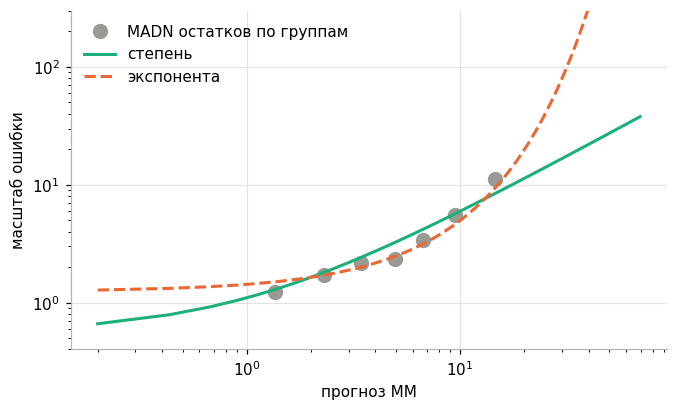

In [67]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(spread["прогноз"], spread["MADN"], "o", color=GREY, ms=9, label="MADN остатков по группам")
t = np.linspace(0.2, fit_mm.max(), 300)
scale0 = np.median(np.abs(r_mm) / first["степень"][1]) / 0.6745
scale1 = np.median(np.abs(r_mm) / first["экспонента"][1]) / 0.6745
ax.plot(t, scale0 * np.exp(first["степень"][0][0] + first["степень"][0][1] * np.log1p(t)), color=AQUA, lw=2, label="степень")
ax.plot(t, scale1 * np.exp(first["экспонента"][0][0] + first["экспонента"][0][1] * t), color=ORANGE, lw=2, ls="--", label="экспонента")
ax.set(xscale="log", yscale="log", ylim=(0.4, 300), xlabel="прогноз MM", ylabel="масштаб ошибки")
ax.legend()
plt.show()

Обе функции проходят через группы с прогнозом от 1 до 15, где лежит почти вся выборка. Дальше экспонента даёт нелепые значения: $h$ доходит до 13 580, у степени до 25.9. Берём степень. $\lambda_2=0.99$, масштаб ошибки растёт почти пропорционально прогнозу. В самой левой группе (прогноз около нуля) степень занижает масштаб примерно в 2 раза.

### 1.9.3. Итерации

In [68]:
f = forms["степень"]
beta_h, rows = beta_mm.copy(), []
for k in range(1, 16):
    lam, h = fit_h(X @ beta_h, y - X @ beta_h, f)
    beta_new, sigma_h = mm_fit(X / h[:, None], y / h)
    shift = np.max(np.abs(beta_new - beta_h))
    beta_h = beta_new
    rows.append([k, *lam, *beta_h, sigma_h, shift])
    if shift < 1e-3:
        break
pd.DataFrame(rows, columns=["шаг", "λ1", "λ2"] + names + ["σ", "сдвиг β"]).set_index("шаг")

,λ1,λ2,const,members,decade,spring,oxygen,nepal,σ,сдвиг β
шаг,,,,,,,,,,
1,-0.974,0.993,-1.859,0.664,0.511,0.545,1.189,0.750,1.381,0.435
2,-1.320,1.201,-1.980,0.668,0.394,0.763,1.224,0.619,1.458,0.218
3,-1.331,1.214,-2.061,0.677,0.352,0.872,1.219,0.590,1.463,0.109
4,-1.343,1.217,-2.080,0.680,0.334,0.906,1.216,0.579,1.472,0.034
5,-1.344,1.217,-2.086,0.681,0.327,0.919,1.213,0.575,1.473,0.013
6,-1.348,1.219,-2.087,0.682,0.323,0.925,1.212,0.572,1.475,0.005
7,-1.349,1.219,-2.088,0.682,0.322,0.927,1.211,0.571,1.475,0.002
8,-1.350,1.219,-2.088,0.682,0.321,0.928,1.210,0.571,1.475,0.001


In [69]:
Xh, yh = X / h[:, None], y / h
u_h = (yh - Xh @ beta_h) / sigma_h
se_h = sandwich_se(Xh, psi_bi(u_h, C1), dpsi_bi(u_h, C1), sigma_h)
pd.DataFrame({"MM": beta_mm, "SE MM": se_mm, "MM с h(x)": beta_h, "SE MM с h(x)": se_h,
              "SE: во сколько раз меньше": se_mm / se_h}, index=names)

,MM,SE MM,MM с h(x),SE MM с h(x),SE: во сколько раз меньше
const,-2.012,0.325,-2.088,0.118,2.759
members,0.725,0.051,0.682,0.019,2.640
decade,0.926,0.116,0.321,0.036,3.235
spring,0.109,0.290,0.928,0.117,2.479
oxygen,1.005,0.172,1.210,0.065,2.659
nepal,1.139,0.117,0.571,0.070,1.683


### 1.9.4. Что изменилось

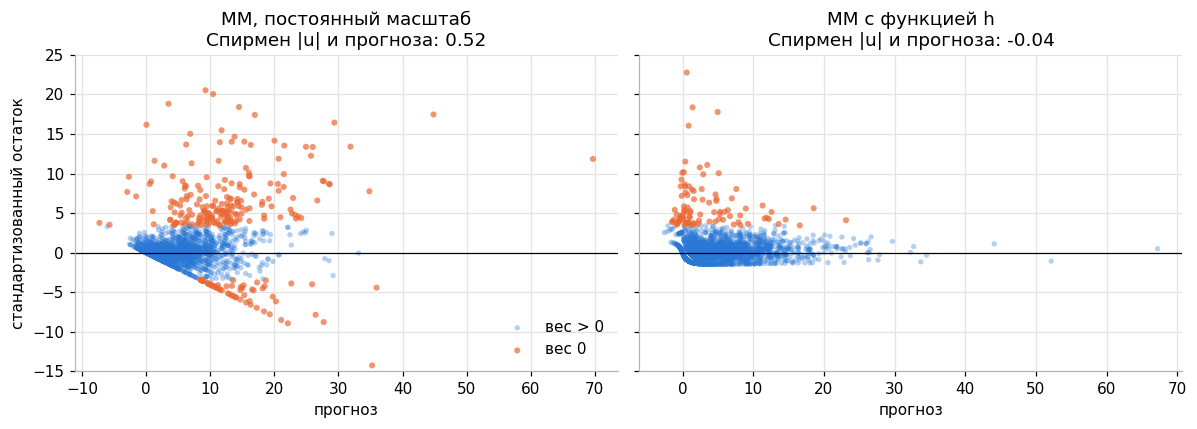

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, u_, fit_, title in [(axes[0], u_mm, fit_mm, "MM, постоянный масштаб"), (axes[1], u_h, X @ beta_h, "MM с функцией h")]:
    mask = np.abs(u_) > C1
    ax.scatter(fit_[~mask], u_[~mask], s=12, alpha=0.35, color=BLUE, edgecolor="none", label="вес > 0")
    ax.scatter(fit_[mask], u_[mask], s=16, alpha=0.7, color=ORANGE, edgecolor="none", label="вес 0")
    ax.axhline(0, color="black", lw=0.8)
    rho_s = stats.spearmanr(np.abs(u_), fit_).statistic
    ax.set(title=f"{title}\nСпирмен |u| и прогноза: {rho_s:.2f}", xlabel="прогноз", ylim=(-15, 25))
axes[0].set_ylabel("стандартизованный остаток")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

In [71]:
out_h = np.abs(u_h) > C1
print("выбросов при постоянном масштабе:", out.sum(), f"({out.mean():.1%})")
print("выбросов с функцией h:           ", out_h.sum(), f"({out_h.mean():.1%})")
print("общих:", (out & out_h).sum(), "  из них вверх:", (u_h[out_h] > 0).sum(), " вниз:", (u_h[out_h] < 0).sum())

выбросов при постоянном масштабе: 258 (10.9%)
выбросов с функцией h:            95 (4.0%)
общих: 43   из них вверх: 95  вниз: 0


In [72]:
kind = np.select([out & out_h, out, out_h], ["выброс в обеих моделях", "только при постоянном масштабе", "только с функцией h"], "не выброс")
data.groupby(kind)[["members", "hired_staff"]].median().assign(экспедиций=pd.Series(kind).value_counts())

,members,hired_staff,экспедиций
выброс в обеих моделях,10.000,28.000,43
не выброс,4.000,3.000,2067
только при постоянном масштабе,17.000,22.000,215
только с функцией h,2.000,4.000,52


In [73]:
data.assign(прогноз=X @ beta_h, u=u_h).sort_values("u", ascending=False).head(10)[
    ["expedition_id", "year", "season", "members", "hired_staff", "прогноз", "u"]]

,expedition_id,year,season,members,hired_staff,прогноз,u
447,EVER35201,1935,Summer,7,16,0.601,22.775
572,EVER00141,2000,Spring,2,22,1.415,18.376
448,EVER36101,1936,Spring,12,65,4.972,17.785
221,EVER94312,1994,Autumn,2,14,0.865,16.056
1971,EVER17401,2017,Winter,2,7,0.394,11.509
638,EVER01146,2001,Spring,5,30,3.494,11.096
442,EVER21101,1921,Spring,9,21,2.444,10.771
762,EVER03169,2003,Spring,1,5,0.189,10.184
296,EVER96102,1996,Spring,1,4,-0.036,10.099
444,EVER24101,1924,Spring,11,40,5.115,10.043


In [74]:
pd.crosstab(data["year"] // 10 * 10, out_h).rename(columns={False: "обычные", True: "выбросы"}).assign(
    доля=lambda t: t["выбросы"] / t.sum(axis=1))

col_0,обычные,выбросы,доля
year,,,
1920,0,3,1.000
1930,1,4,0.800
1940,1,0,0.000
1950,6,3,0.333
1960,8,4,0.333
1970,21,6,0.222
1980,134,7,0.050
1990,315,16,0.048
2000,721,24,0.032


Повторим отбор переменных на преобразованных данных:

In [75]:
XFh = XF / h[:, None]
beta_fh, sigma_fh = mm_fit(XFh, yh)
w_fh = w_bi((yh - XFh @ beta_fh) / sigma_fh, C1)
path_h = backward(rfpe, XFh, yh, sigma_fh, w_fh)
path_h.assign(критерий=path_h["критерий"].map("{:.5f}".format))

,убран,критерий,осталось
0,—,0.23513,"members, decade, spring, oxygen, nepal, commer..."
1,agency,0.23501,"members, decade, spring, oxygen, nepal, commer..."
2,spring,0.23515,"members, decade, oxygen, nepal, commercial"
3,decade,0.23920,"members, oxygen, nepal, commercial"
4,commercial,0.24583,"members, oxygen, nepal"
5,nepal,0.25356,"members, oxygen"
6,oxygen,0.28404,members


Сходимость за 8 шагов. Корреляция Спирмена между $|u|$ и прогнозом упала с 0.52 до −0.04, стандартные ошибки уменьшились в 1.7–3.2 раза. Выбросов стало 95 вместо 258, общих 43. Перестали быть выбросами 215 крупных экспедиций (медиана 17 участников и 22 нанятых): при таком размере большой разброс нормален. Появились 52 маленьких (2 участника и 4 нанятых), которых общий масштаб не замечал. В обеих моделях выбросами остались экспедиции, где на 10 участников приходится 28 нанятых.

Все 95 выбросов вверх. В десятке самых больших остатков четыре ранние экспедиции (1921, 1924, 1935, 1936) и шесть маленьких современных, от 1 до 5 участников с 4–30 нанятыми. Из восьми экспедиций 1920–30-х годов выбросами остались семь.

Коэффициент при `decade` теперь 0.32 вместо 0.93, при `spring` 0.93 ($z=7.9$) вместо 0.11, при `nepal` 0.57 вместо 1.14. Похоже, при постоянном масштабе тренд определяли крупные экспедиции, а теперь больше весят маленькие, у которых прирост в людях меньше. На преобразованных данных RFPE убирает только `agency` (0.23501 против 0.23513).

Снизу остатки упираются примерно в −1.5, потому что персонала не бывает меньше нуля. Распределение ошибок несимметрично, и свободный член смещён. Наклоны при ошибках, независимых от $x$, остаются состоятельными.

## 1.10. Итог задания 1

In [76]:
pd.DataFrame([beta_ls, beta_gm, beta_mm, beta_h], columns=names, index=["МНК", "GM", "MM", "MM с h(x)"])

,const,members,decade,spring,oxygen,nepal
МНК,-4.796,0.895,0.158,2.370,1.296,2.968
GM,-2.687,0.818,1.081,0.115,1.122,1.661
MM,-2.012,0.725,0.926,0.109,1.005,1.139
MM с h(x),-2.088,0.682,0.321,0.928,1.210,0.571


МНК тренда по годам не видит (0.16, p = 0.22). GM и MM показывают рост на 0.9–1.1 человека за десятилетие, с учётом гетероскедастичности остаётся 0.32 при SE 0.04. Знак и значимость сохраняются, величина зависит от модели масштаба. GM и MM согласны по знакам, но не по величине: `members` 0.82 и 0.73. S-оценка на этих данных неоднозначна, MM от неё не зависит. Учёт гетероскедастичности сократил выбросы с 258 до 95 и уменьшил SE в 1.7–3.2 раза.

Итоговая модель (MM с $h$): на одного дополнительного участника 0.68 человека персонала, кислород добавляет 1.2, весна 0.9, непальская сторона 0.6, десятилетие 0.3.

---
# Задание 2. Логистическая регрессия

## 2.1. Данные и модель

In [77]:
data["termination_reason"].value_counts()

termination_reason
Success (main peak)        1522
Bad weather                 300
Other                       160
Illness, exhaustion         127
Bad conditions               85
Accident                     53
Lack of supplies             50
Too difficult                39
Lack of time                 11
Did not attempt climb        11
Unknown                       9
Success (claimed)             4
Did not reach base camp       3
Attempt rumoured              2
Success (subpeak)             1
Name: count, dtype: int64

Успехом считаем `Success (main peak)`. Экспедиции, которые не начали восхождение, не дошли до базового лагеря, известны по слухам, закончились по неизвестной причине или заявили спорный успех, убираем: исход у них не определён. Таких строк 29. `Success (subpeak)` одна, она идёт в неудачи, до главной вершины группа не дошла.

In [78]:
unclear = ["Did not attempt climb", "Attempt rumoured", "Did not reach base camp", "Unknown", "Success (claimed)"]
climb = data[~data["termination_reason"].isin(unclear)].copy()
climb["success"] = (climb["termination_reason"] == "Success (main peak)").astype(int)
print("экспедиций:", len(climb), "  доля успеха:", round(climb["success"].mean(), 3))
pd.crosstab(climb["oxygen"], climb["success"], normalize="index")

экспедиций: 2348   доля успеха: 0.648


success,0,1
oxygen,,
0,0.932,0.068
1,0.184,0.816


С кислородом успешны 82 % экспедиций, без него 7 %. Кислород включают высоко на горе: кто повернул назад ниже, попадает в «без кислорода» как раз потому, что не дошёл. Признак почти содержит ответ, в модель его не берём. Остаются размер команды, персонал, год, сезон и сторона горы, они известны до выхода.

In [79]:
bins = pd.cut(climb["hired_staff"], [-1, 0, 1, 2, 3, 5, 8, 12, 20, 40, 100],
              labels=["0", "1", "2", "3", "4–5", "6–8", "9–12", "13–20", "21–40", "41+"])
climb.groupby(bins, observed=True)["success"].agg(доля_успеха="mean", экспедиций="size").T

hired_staff,0,1,2,3,4–5,6–8,9–12,13–20,21–40,41+
доля_успеха,0.282,0.580,0.647,0.676,0.706,0.795,0.781,0.833,0.845,0.811
экспедиций,390.000,312.000,272.000,188.000,303.000,268.000,233.000,203.000,142.000,37.000


In [80]:
feats2 = ["members", "hired_staff", "decade", "spring", "nepal"]
names2 = ["const"] + feats2
XS = np.column_stack([np.ones(len(climb)), climb[feats2]]).astype(float)
ys = climb["success"].to_numpy(float)
ns, ps = XS.shape
print("n =", ns, " p =", ps)

n = 2348  p = 6


Модель: $P(y_i=1\mid x_i)=F(\beta'x_i)$, $F(t)=e^t/(1+e^t)$, то есть

$$\ln\frac{P(\text{успех})}{P(\text{неудача})}=\beta_0+\beta_1\,\mathrm{members}+\beta_2\,\mathrm{hired\_staff}+\beta_3\,\mathrm{decade}+\beta_4\,\mathrm{spring}+\beta_5\,\mathrm{nepal}.$$

## 2.2. Классические оценки: максимальное правдоподобие

Обозначим $p_i=F(\beta'x_i)$. Логарифм правдоподобия и уравнения для ОМП:

$$\ell(\beta)=\sum_i\left[y_i\ln p_i+(1-y_i)\ln(1-p_i)\right],\qquad \sum_i(y_i-p_i)\,x_i=0 .$$

Решаем методом Ньютона: $\beta_{k+1}=\beta_k+\left(X'DX\right)^{-1}X'(y-p)$, $D=\mathrm{diag}(p_i(1-p_i))$.

Множитель $y_i-p_i$ ограничен, но $x_i$ нет, поэтому опасны точки с далёким $x$ и «неправильным» ответом. В линейной регрессии такие точки могут увести наклон в бесконечность, в логистической прижимают его к нулю (Croux, Flandre, Haesbroeck, 2002).

In [81]:
def prob(X, b):
    return 1 / (1 + np.exp(-X @ b))

b, rows = np.zeros(ps), []
for k in range(25):
    pr = prob(XS, b)
    rows.append([k, np.sum(ys * np.log(pr) + (1 - ys) * np.log(1 - pr)), *b])
    step = np.linalg.solve((XS.T * (pr * (1 - pr))) @ XS, XS.T @ (ys - pr))
    b = b + step
    if np.max(np.abs(step)) < 1e-10:
        break
beta_mle = b
pd.DataFrame(rows, columns=["итерация", "ln L"] + names2).set_index("итерация")

,ln L,const,members,hired_staff,decade,spring,nepal
итерация,,,,,,,
0,-1627.510,0.000,0.000,0.000,0.000,0.000,0.000
1,-1313.594,-1.395,0.031,0.024,0.272,1.427,0.261
2,-1289.580,-1.793,0.046,0.049,0.393,1.604,0.262
3,-1287.759,-1.893,0.049,0.061,0.427,1.646,0.240
4,-1287.743,-1.902,0.049,0.063,0.429,1.650,0.238
5,-1287.743,-1.902,0.049,0.063,0.429,1.650,0.238
6,-1287.743,-1.902,0.049,0.063,0.429,1.650,0.238


In [82]:
pr = prob(XS, beta_mle)
se_mle = np.sqrt(np.diag(np.linalg.inv((XS.T * (pr * (1 - pr))) @ XS)))
z = beta_mle / se_mle
pd.DataFrame({"ОМП": beta_mle, "SE": se_mle, "z": z, "p-value": 2 * stats.norm.sf(np.abs(z)),
              "отношение шансов": np.exp(beta_mle)}, index=names2)

,ОМП,SE,z,p-value,отношение шансов
const,-1.902,0.181,-10.508,0.000,0.149
members,0.049,0.011,4.582,0.000,1.050
hired_staff,0.063,0.010,6.067,0.000,1.065
decade,0.429,0.050,8.501,0.000,1.536
spring,1.650,0.167,9.907,0.000,5.209
nepal,0.238,0.102,2.341,0.019,1.268


Значимы все коэффициенты, слабее всего `nepal` ($p=0.02$). Один нанятый человек увеличивает шансы на 6.5 %, весна в 5.2 раза, десятилетие в 1.5 раза. Эффект персонала выглядит слабым. Доля успеха растёт с 0.28 без персонала до 0.80 при 6–8 людях, логит меняется на 2.3. При коэффициенте 0.063 для этого нужно около 36 человек.

## 2.3. Взвешенные M-оценки

### 2.3.1. Идея

ОМП минимизирует сумму квадратов девиансных остатков $\sum_i d_i^2$, где

$$d_i^2=-2\left[y_i\ln p_i+(1-y_i)\ln(1-p_i)\right].$$

Девианс не ограничен: если $y_i=0$, а $p_i\to1$, то $d_i^2\to\infty$. Bianco и Yohai (1996) заменили $d^2$ на $\rho(d^2)$ с медленно растущей $\rho$ и добавили поправку $q$, без которой оценка несостоятельна по Фишеру. Croux и Haesbroeck (2003) предложили конкретную $\psi=\rho'$ и веса по $x$. Взвешенная M-оценка (7.17) минимизирует

$$M(\beta)=\sum_{i=1}^n w_i\left\{\rho\!\left(d_i^2\right)+q(p_i)\right\},\qquad q(u)=v(u)+v(1-u),\quad v(u)=2\int_0^u\psi(-2\ln t)\,dt ,$$

$$\psi(t)=\exp\!\left(-\sqrt{\max(t,c)}\right),\quad c=0.5,\qquad w_i=W(d(x_i)).$$

Функция $\rho$ отвечает за выбросы в ответе, веса $w_i$ за далёкие $x$. При $w_i=1$ получается M-оценка без весов, при $\rho(t)=t$ и $q=0$ взвешенная ОМП (WMLE).

### 2.3.2. Функции $\rho$ и $v$ в явном виде

Интегрируя $\psi$, получаем

$$\rho(t)=\begin{cases}t\,e^{-\sqrt c},&t\le c\\ c\,e^{-\sqrt c}+2(1+\sqrt c)e^{-\sqrt c}-2(1+\sqrt t)e^{-\sqrt t},&t>c\end{cases}$$

Для $v$ замена $t=e^{-s/2}$, $s=m^2$ при $u\le e^{-c/2}$ даёт

$$v(u)=2\int_{m_0}^{\infty}m\,e^{-m-m^2/2}dm=2\sqrt e\left[e^{-(m_0+1)^2/2}-\sqrt{2\pi}\,\bigl(1-\Phi(m_0+1)\bigr)\right],\quad m_0=\sqrt{-2\ln u},$$

а при $u>e^{-c/2}$ функция линейна с наклоном $2e^{-\sqrt c}$.

In [83]:
CH = 0.5
E = np.exp(-np.sqrt(CH))

def psi_ch(t):
    return np.exp(-np.sqrt(np.maximum(t, CH)))

def rho_ch(t):
    s = np.sqrt(np.maximum(t, CH))
    return np.where(t <= CH, t * E, CH * E + 2 * (1 + np.sqrt(CH)) * E - 2 * (1 + s) * np.exp(-s))

def v_ch(u):
    u0 = np.exp(-CH / 2)
    m0 = np.sqrt(-2 * np.log(np.minimum(u, u0)))
    low = 2 * np.sqrt(np.e) * (np.exp(-(m0 + 1) ** 2 / 2) - np.sqrt(2 * np.pi) * stats.norm.sf(m0 + 1))
    return low + 2 * E * np.maximum(u - u0, 0)

Проверка формул численным интегрированием:

In [84]:
us, ts = [0.05, 0.3, 0.7, 0.9, 0.99], [0.2, 0.5, 1, 4, 12]
pd.DataFrame({"u": us, "v(u)": [float(v_ch(np.array(u))) for u in us],
              "v численно": [2 * quad(lambda t: float(psi_ch(-2 * np.log(t))), 0, u)[0] for u in us],
              "t": ts, "ρ(t)": [float(rho_ch(np.array(t))) for t in ts],
              "ρ численно": [quad(lambda s: float(psi_ch(s)), 0, t)[0] for t in ts]}).map("{:.5g}".format)

,u,v(u),v численно,t,ρ(t),ρ численно
0,0.05,0.0063127,0.0063127,0.2,0.098614,0.098614
1,0.3,0.08283,0.08283,0.5,0.24653,0.24653
2,0.7,0.3326,0.3326,1,0.45846,0.45846
3,0.9,0.52466,0.52466,4,1.118,1.118
4,0.99,0.61341,0.61341,12,1.6505,1.6505


### 2.3.3. Веса по $x$

Робастное расстояние считаем по трём непрерывным признакам через MCD, вес $W(d)=\min(1,c/d)$ с $c=\sqrt{\chi^2_{3;\,0.975}}$.

In [85]:
ZS = climb[["members", "hired_staff", "decade"]].to_numpy()
mcd2 = MinCovDet(support_fraction=0.75, random_state=0).fit(ZS)
ds = np.sqrt(mcd2.mahalanobis(ZS))
cut_s = np.sqrt(stats.chi2.ppf(0.975, 3))
w_s = np.minimum(1, cut_s / ds)
print(f"порог {cut_s:.2f}, дальше порога {np.mean(ds > cut_s):.1%}, сумма весов {w_s.sum():.0f} из {ns}")
climb[["expedition_id", "year", "members", "hired_staff", "success"]].assign(d=ds, w=w_s).sort_values("w").head(8)

порог 3.06, дальше порога 27.6%, сумма весов 2084 из 2348


,expedition_id,year,members,hired_staff,success,d,w
460,EVER60102,1960,29,99,1,40.505,0.075
468,EVER75102,1975,35,99,1,37.903,0.081
1136,EVER08101,2008,76,0,1,33.909,0.090
448,EVER36101,1936,12,65,0,31.524,0.097
96,EVER88101,1988,99,99,1,30.121,0.102
386,EVER73101,1973,65,88,1,27.168,0.113
407,EVER64101,1964,20,60,0,24.643,0.124
463,EVER66101,1966,20,60,0,24.510,0.125


### 2.3.4. Функция потерь и градиент

$$\frac{\partial M}{\partial\beta}=-2\sum_i w_i\left[\psi(d_i^2)(y_i-p_i)-p_i(1-p_i)\bigl(\psi(-2\ln p_i)-\psi(-2\ln(1-p_i))\bigr)\right]x_i .$$

Вычитаемое слагаемое равно $\mathrm E\left[\psi(d_i^2)(y_i-p_i)\mid x_i\right]$, поэтому в истинной точке среднее градиента равно нулю и оценка состоятельна по Фишеру.

In [86]:
def deviance(b, X, y):
    pr = np.clip(prob(X, b), 1e-12, 1 - 1e-12)
    return pr, -2 * (y * np.log(pr) + (1 - y) * np.log(1 - pr))

def wm_loss(b, X, y, w):
    pr, d2 = deviance(b, X, y)
    return np.mean(w * (rho_ch(d2) + v_ch(pr) + v_ch(1 - pr)))

def wm_score(b, X, y, w):
    pr, d2 = deviance(b, X, y)
    mean = pr * (1 - pr) * (psi_ch(-2 * np.log(pr)) - psi_ch(-2 * np.log(1 - pr)))
    return -2 * (w * (psi_ch(d2) * (y - pr) - mean))[:, None] * X

def wm_grad(b, X, y, w):
    return wm_score(b, X, y, w).mean(axis=0)

print("ошибка градиента:", check_grad(wm_loss, wm_grad, beta_mle, XS, ys, w_s))

ошибка градиента: 5.2749770923651715e-08


### 2.3.5. Минимизация

Функция невыпуклая, поэтому запускаем BFGS из трёх точек: нуля, ОМП и взвешенной ОМП.

In [87]:
def wmle_loss(b, X, y, w):
    return np.mean(w * deviance(b, X, y)[1])

def wmle_score(b, X, y, w):
    pr, _ = deviance(b, X, y)
    return -2 * (w * (y - pr))[:, None] * X

def wmle_grad(b, X, y, w):
    return wmle_score(b, X, y, w).mean(axis=0)

beta_wmle = minimize(wmle_loss, beta_mle, args=(XS, ys, w_s), jac=wmle_grad, method="BFGS").x
starts = {"ноль": np.zeros(ps), "ОМП": beta_mle, "WMLE": beta_wmle}
runs = {k: minimize(wm_loss, b0, args=(XS, ys, w_s), jac=wm_grad, method="BFGS") for k, b0 in starts.items()}
pd.DataFrame({k: [r.nit, r.fun, np.max(np.abs(r.jac)), *r.x] for k, r in runs.items()},
             index=["итераций", "M(β)", "max |градиент|"] + names2).T.map("{:.5f}".format)

,итераций,M(β),max |градиент|,const,members,hired_staff,decade,spring,nepal
ноль,35.00000,0.77696,0.00000,-2.60593,0.02499,0.22107,0.33272,2.24588,0.03180
ОМП,32.00000,0.77696,0.00001,-2.60601,0.02499,0.22108,0.33273,2.24590,0.03184
WMLE,31.00000,0.77696,0.00000,-2.60620,0.02499,0.22109,0.33271,2.24612,0.03184


In [88]:
beta_wm = min(runs.values(), key=lambda r: r.fun).x
beta_m = minimize(wm_loss, beta_mle, args=(XS, ys, np.ones(ns)), jac=wm_grad, method="BFGS").x
pd.DataFrame([beta_mle, beta_wmle, beta_m, beta_wm], columns=names2,
             index=["ОМП", "WMLE: веса, без ρ", "M: ρ, без весов", "WM: ρ и веса"])

,const,members,hired_staff,decade,spring,nepal
ОМП,-1.902,0.049,0.063,0.429,1.650,0.238
"WMLE: веса, без ρ",-2.177,0.040,0.125,0.338,1.924,0.137
"M: ρ, без весов",-2.184,0.034,0.132,0.411,1.879,0.110
WM: ρ и веса,-2.606,0.025,0.221,0.333,2.246,0.032


### 2.3.6. Стандартные ошибки

Снова сэндвич $\frac1nH^{-1}QH^{-1}$: якобиан среднего градиента $H$ считаем численно, $Q=\frac1n\sum_i s_is_i'$ по вкладам наблюдений $s_i$.

In [89]:
def se_by(score, b, w, X=None):
    X = XS if X is None else X
    eps = 1e-5
    H = np.column_stack([(score(b + eps * e, X, ys, w).mean(0) - score(b - eps * e, X, ys, w).mean(0)) / (2 * eps)
                         for e in np.eye(ps)])
    s = score(b, X, ys, w)
    H_inv = np.linalg.inv(H)
    return np.sqrt(np.diag(H_inv @ (s.T @ s / ns) @ H_inv.T) / ns)

one = np.ones(ns)
se_wmle, se_m, se_wm = se_by(wmle_score, beta_wmle, w_s), se_by(wm_score, beta_m, one), se_by(wm_score, beta_wm, w_s)
pd.concat({label: pd.DataFrame({"оценка": b, "SE": se}, index=names2) for label, b, se in
           [("ОМП", beta_mle, se_mle), ("WMLE", beta_wmle, se_wmle), ("M", beta_m, se_m), ("WM", beta_wm, se_wm)]}, axis=1)

ОМП         WMLE            M           WM      
            оценка    SE оценка    SE оценка    SE оценка    SE
const       -1.902 0.181 -2.177 0.195 -2.184 0.230 -2.606 0.268
members      0.049 0.011  0.040 0.014  0.034 0.017  0.025 0.016
hired_staff  0.063 0.010  0.125 0.019  0.132 0.038  0.221 0.033
decade       0.429 0.050  0.338 0.058  0.411 0.065  0.333 0.070
spring       1.650 0.167  1.924 0.176  1.879 0.212  2.246 0.239
nepal        0.238 0.102  0.137 0.104  0.110 0.118  0.032 0.113

Насколько результат зависит от весов: вместо весов Хьюбера возьмём семейство Кэрролла–Педерсона $W(d)=(1-d^2/c^2)^3$ при $d\le c$, из формулы (7.11), с двумя порогами.

In [90]:
rows = {"веса Хьюбера": beta_wm}
for q in (0.99, 0.95):
    c = np.quantile(ds, q)
    w_cp = np.where(ds <= c, (1 - (ds / c) ** 2) ** 3, 0.0)
    rows[f"Кэрролл–Педерсон, c = {c:.1f}"] = minimize(wm_loss, beta_wm, args=(XS, ys, w_cp), jac=wm_grad, method="BFGS").x
pd.DataFrame(rows, index=names2).T

,const,members,hired_staff,decade,spring,nepal
веса Хьюбера,-2.606,0.025,0.221,0.333,2.246,0.032
"Кэрролл–Педерсон, c = 17.6",-2.542,0.022,0.215,0.329,2.202,0.038
"Кэрролл–Педерсон, c = 8.7",-2.981,0.023,0.290,0.298,2.567,-0.005


Коэффициент при персонале 0.063 у ОМП, 0.125 только с весами, 0.132 только с $\rho$, 0.221 у WM. Каждый механизм увеличивает его вдвое, вместе в 3.5 раза. Это соответствует эффекту из 2.2: далёкие точки с неудачей (1964 и 1966 годы, по 60 нанятых, 1936 год, 65 нанятых) прижимают наклон к нулю. `members` у WM незначим (0.025 при SE 0.016), `nepal` исчез (0.03 при SE 0.11), `spring` вырос с 1.65 до 2.25. За робастность платим точностью: SE при персонале 0.033 вместо 0.010.

Мягкие веса Кэрролла–Педерсона ($c=17.6$) дают почти то же, 0.215. Жёсткие ($c=8.7$) дают 0.290: чем слабее вклад крупных экспедиций, тем круче наклон. Похоже, дело в форме зависимости, к этому вернёмся в 2.6.

Доля успеха по группам и средняя вероятность от каждой модели:

In [91]:
calib = pd.DataFrame({"наблюдений": climb.groupby(bins, observed=True).size(),
                      "доля успеха": climb.groupby(bins, observed=True)["success"].mean(),
                      "ОМП": pd.Series(prob(XS, beta_mle), climb.index).groupby(bins, observed=True).mean(),
                      "WM": pd.Series(prob(XS, beta_wm), climb.index).groupby(bins, observed=True).mean()})
calib

,наблюдений,доля успеха,ОМП,WM
hired_staff,,,,
0,390,0.282,0.498,0.414
1,312,0.580,0.588,0.539
2,272,0.647,0.581,0.564
3,188,0.676,0.604,0.613
4–5,303,0.706,0.620,0.656
6–8,268,0.795,0.692,0.769
9–12,233,0.781,0.732,0.843
13–20,203,0.833,0.815,0.940
21–40,142,0.845,0.898,0.991


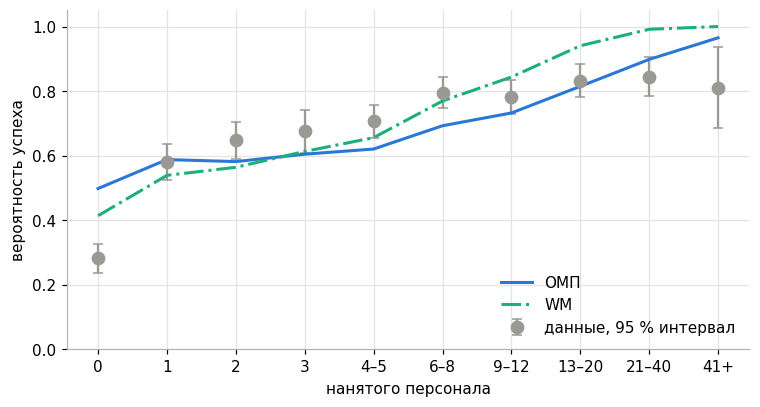

In [92]:
fig, ax = plt.subplots(figsize=(8, 4))
pos = np.arange(len(calib))
err = 1.96 * np.sqrt(calib["доля успеха"] * (1 - calib["доля успеха"]) / calib["наблюдений"])
ax.errorbar(pos, calib["доля успеха"], yerr=err, fmt="o", color=GREY, ms=8, capsize=3, label="данные, 95 % интервал")
ax.plot(pos, calib["ОМП"], color=BLUE, lw=2, label="ОМП")
ax.plot(pos, calib["WM"], color=AQUA, lw=2, ls="-.", label="WM")
ax.set(xticks=pos, xticklabels=calib.index, xlabel="нанятого персонала", ylabel="вероятность успеха", ylim=(0, 1.05))
ax.legend(loc="lower right")
plt.show()

Без персонала ОМП обещает 0.50, WM 0.41, в данных 0.28. При 4–8 людях WM тоже ближе к данным. При 13 и больше WM завышает: 0.94 против 0.83, потом 0.99 против 0.85. Доля успеха после 6–8 человек почти не растёт, а прямая в логитах выйти на плато не может. ОМП усредняет маленькие и крупные экспедиции, WM описывает большинство: 1733 экспедиции из 2348 нанимали не больше 8 человек.

## 2.4. Сравнение функций потерь

### 2.4.1. Потеря одного наблюдения

Наблюдение с $y=1$, по горизонтали линейный предиктор $\eta=\beta'x$. Слева потеря, справа вклад в оценочное уравнение (множитель перед $x_i$). Потеря Bianco–Yohai сдвинута на константу так, чтобы при $\eta\to\infty$ обе потери стремились к нулю.

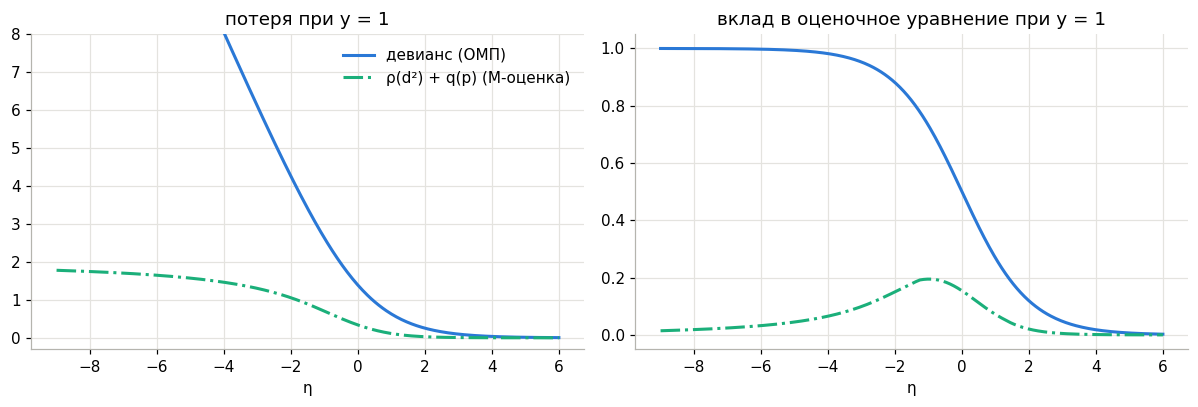

предел ρ(t) при t → ∞: 1.93


In [93]:
eta = np.linspace(-9, 6, 400)
pe = 1 / (1 + np.exp(-eta))
d2_1 = -2 * np.log(pe)
by = rho_ch(d2_1) + v_ch(pe) + v_ch(1 - pe)
by = by - by[-1]
mean = pe * (1 - pe) * (psi_ch(-2 * np.log(pe)) - psi_ch(-2 * np.log(1 - pe)))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(eta, d2_1, color=BLUE, lw=2, label="девианс (ОМП)")
axes[0].plot(eta, by, color=AQUA, lw=2, ls="-.", label="ρ(d²) + q(p) (M-оценка)")
axes[0].set(xlabel="η", title="потеря при y = 1", ylim=(-0.3, 8))
axes[0].legend()
axes[1].plot(eta, 1 - pe, color=BLUE, lw=2)
axes[1].plot(eta, psi_ch(d2_1) * (1 - pe) - mean, color=AQUA, lw=2, ls="-.")
axes[1].set(xlabel="η", title="вклад в оценочное уравнение при y = 1")
plt.tight_layout()
plt.show()
print("предел ρ(t) при t → ∞:", round(float(rho_ch(np.array(1e6))), 3))

На графике множитель перед $x$. Полное влияние пропорционально ещё и $\|x\|$, при далёком $x$ его ограничивает только вес $w_i$.

### 2.4.2. Каждая оценка под каждой потерей

In [94]:
cross2 = pd.DataFrame({"девианс": [wmle_loss(b, XS, ys, one) for b in (beta_mle, beta_wmle, beta_m, beta_wm)],
                       "взвешенный девианс": [wmle_loss(b, XS, ys, w_s) for b in (beta_mle, beta_wmle, beta_m, beta_wm)],
                       "M": [wm_loss(b, XS, ys, one) for b in (beta_mle, beta_wmle, beta_m, beta_wm)],
                       "WM": [wm_loss(b, XS, ys, w_s) for b in (beta_mle, beta_wmle, beta_m, beta_wm)]},
                      index=["ОМП", "WMLE", "M", "WM"])
cross2.map("{:.4f}".format)

,девианс,взвешенный девианс,M,WM
ОМП,1.0969,0.9898,0.8767,0.7829
WMLE,1.1172,0.9803,0.8756,0.7786
M,1.1161,0.9813,0.8753,0.7788
WM,1.1865,0.9946,0.8771,0.7770


In [95]:
((cross2 / cross2.min() - 1) * 100).rename(columns=lambda c: c + ", проигрыш %").map("{:.2f}".format)

,"девианс, проигрыш %","взвешенный девианс, проигрыш %","M, проигрыш %","WM, проигрыш %"
ОМП,0.00,0.96,0.16,0.76
WMLE,1.85,0.00,0.04,0.21
M,1.75,0.10,0.00,0.23
WM,8.17,1.46,0.21,0.00


### 2.4.3. Откуда берётся потеря

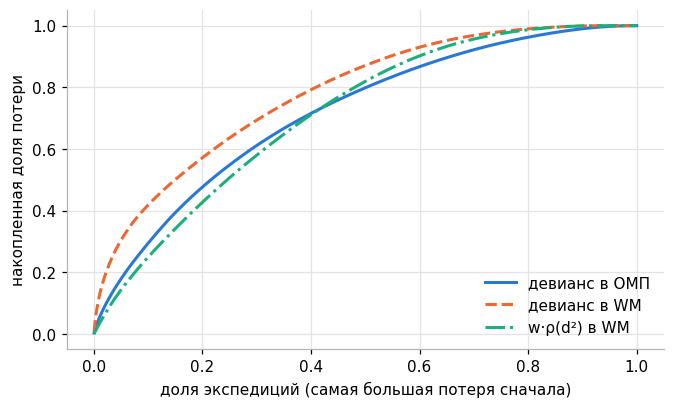

In [96]:
d2_mle, d2_wm = deviance(beta_mle, XS, ys)[1], deviance(beta_wm, XS, ys)[1]
parts2 = {"девианс в ОМП": (BLUE, "-", d2_mle), "девианс в WM": (ORANGE, "--", d2_wm),
          "w·ρ(d²) в WM": (AQUA, "-.", w_s * rho_ch(d2_wm))}
fig, ax = plt.subplots(figsize=(7, 4))
share = np.arange(1, ns + 1) / ns
for label, (color, ls, val) in parts2.items():
    ax.plot(share, np.cumsum(np.sort(val)[::-1]) / val.sum(), color=color, ls=ls, lw=2, label=label)
ax.set(xlabel="доля экспедиций (самая большая потеря сначала)", ylabel="накопленная доля потери")
ax.legend(loc="lower right")
plt.show()

In [97]:
pd.DataFrame({label: [np.sort(val)[::-1][: int(q * ns)].sum() / val.sum() for q in (0.01, 0.05, 0.10)]
              for label, (_, _, val) in parts2.items()}, index=["1 % с наибольшей потерей", "5 %", "10 %"])

,девианс в ОМП,девианс в WM,w·ρ(d²) в WM
1 % с наибольшей потерей,0.053,0.123,0.033
5 %,0.179,0.304,0.144
10 %,0.294,0.418,0.249


### 2.4.4. Профиль по коэффициенту при персонале

Как и в задании 1, фиксируем $\beta_2$ и минимизируем по остальным. Потери измерены в разных единицах, поэтому обе кривые приведены к одной шкале: 0 в минимуме, 1 при $\beta_2=0$ (персонал не учитывается).

In [98]:
def profile2(loss, grad, w, b_start, values, j=2):
    rest = [k for k in range(ps) if k != j]
    out, b0 = [], b_start[rest]
    for val in values:
        full = lambda b: np.insert(b, j, val)
        res = minimize(lambda b: loss(full(b), XS, ys, w), b0, jac=lambda b: grad(full(b), XS, ys, w)[rest], method="BFGS")
        out.append(res.fun)
    return np.array(out)

g2 = np.linspace(-0.05, 0.6, 53)
prof_mle = profile2(wmle_loss, wmle_grad, one, beta_mle, g2)
prof_wm = profile2(wm_loss, wm_grad, w_s, beta_wm, g2)
print("минимум профиля: девианс {:.3f}, WM {:.3f}".format(g2[prof_mle.argmin()], g2[prof_wm.argmin()]))

минимум профиля: девианс 0.062, WM 0.225


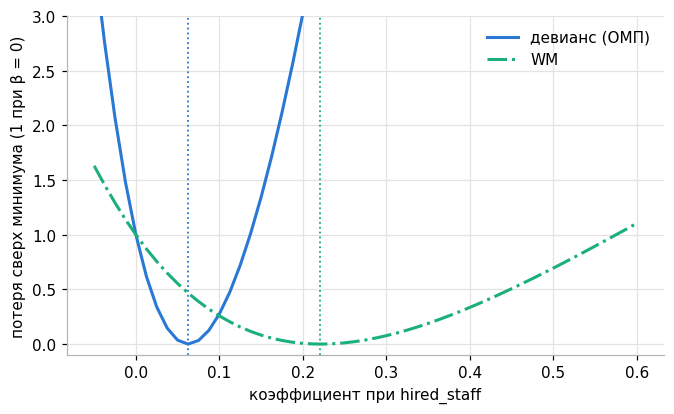

In [99]:
fig, ax = plt.subplots(figsize=(7, 4))
for v_, color, ls, label, b in [(prof_mle, BLUE, "-", "девианс (ОМП)", beta_mle), (prof_wm, AQUA, "-.", "WM", beta_wm)]:
    ax.plot(g2, (v_ - v_.min()) / (np.interp(0, g2, v_) - v_.min()), color=color, ls=ls, lw=2, label=label)
    ax.axvline(b[2], color=color, ls=":", lw=1.2)
ax.set(xlabel="коэффициент при hired_staff", ylabel="потеря сверх минимума (1 при β = 0)", ylim=(-0.1, 3))
ax.legend(loc="upper right")
plt.show()

### 2.4.5. Поверхность по двум коэффициентам

Срез по коэффициентам при `members` и `hired_staff`, остальные три зафиксированы в своей оценке (слева в ОМП, справа в WM).

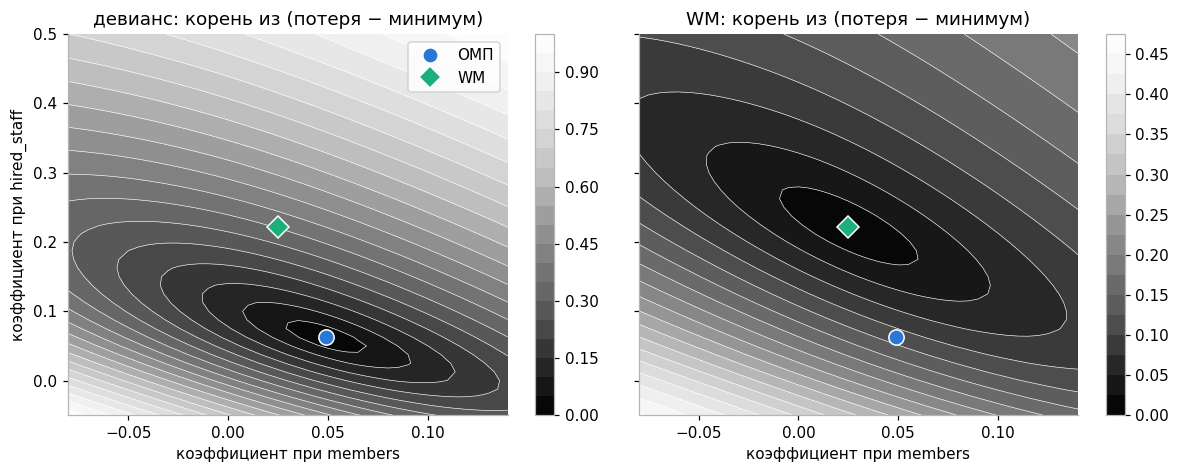

In [100]:
bm, bh = np.meshgrid(np.linspace(-0.08, 0.14, 45), np.linspace(-0.05, 0.5, 45))

def surface(loss, w, b):
    out = np.empty(bm.size)
    for i, (a, c) in enumerate(zip(bm.ravel(), bh.ravel())):
        bb = b.copy()
        bb[1], bb[2] = a, c
        out[i] = loss(bb, XS, ys, w)
    return out.reshape(bm.shape)

surf2 = {"девианс": surface(wmle_loss, one, beta_mle), "WM": surface(wm_loss, w_s, beta_wm)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, (title, val) in zip(axes, surf2.items()):
    root = np.sqrt(val - val.min())
    cs = ax.contourf(bm, bh, root, 20, cmap="Greys_r")
    ax.contour(bm, bh, root, 20, colors="white", linewidths=0.4)
    ax.locator_params(axis="x", nbins=5)
    ax.plot(*beta_mle[1:3], "o", color=BLUE, ms=10, mec="white", label="ОМП")
    ax.plot(*beta_wm[1:3], "D", color=AQUA, ms=10, mec="white", label="WM")
    ax.set(title=f"{title}: корень из (потеря − минимум)", xlabel="коэффициент при members")
    ax.grid(False)
    fig.colorbar(cs, ax=ax)
axes[0].set_ylabel("коэффициент при hired_staff")
axes[0].legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

### 2.4.6. Что видно из сравнения

При уверенно ошибочном прогнозе девианс растёт линейно по $\eta$, а потеря M-оценки не превышает 1.93. Вклад наблюдения после $\eta\approx-1$ убывает, явный выброс на оценку почти не влияет.

По перекрёстной таблице ОМП проигрывает WM по потере WM 0.8 %, а WM проигрывает ОМП по девиансу 8.2 %. Сравнивать проценты между столбцами нельзя, у WM большая часть потери постоянна (слагаемое $q$).

В решении WM 1 % экспедиций даёт 12 % девианса и только 3 % взвешенной $\rho(d^2)$. WM грубо ошибается на этих экспедициях, но их вклад в оценку мал.

Минимум профиля у ОМП 0.063, у WM 0.221. Форма у кривых разная: девианс справа растёт круто, у WM рост умеренный.

При заданном $x$ остаток логистической регрессии принимает два значения, и форма $\rho$ целиком видна на графике одной потери как функции $\eta$, этот рисунок полезнее остальных. Контуры показывают срез, на котором остальные коэффициенты заморожены, поэтому точка чужой оценки на каждом графике условна. Профиль точнее.

## 2.5. Какие наблюдения модель считает нетипичными

In [101]:
pw = prob(XS, beta_wm)
view2 = climb[["expedition_id", "year", "season", "highpoint_date", "members", "hired_staff", "success", "termination_reason"]].assign(
    вероятность=pw, d=ds, вес_x=w_s, вес_отклика=psi_ch(d2_wm) / E)
view2[view2["success"] == 0].sort_values("вероятность", ascending=False).head(10)

,expedition_id,year,season,highpoint_date,members,hired_staff,success,termination_reason,вероятность,d,вес_x,вес_отклика
463,EVER66101,1966,Spring,NaN,20,60,0,Accident,1.000,24.510,0.125,0.014
407,EVER64101,1964,Spring,NaN,20,60,0,Other,1.000,24.643,0.124,0.014
448,EVER36101,1936,Spring,1936-05-14,12,65,0,Bad weather,1.000,31.524,0.097,0.015
401,EVER71101,1971,Spring,1971-05-20,31,55,0,Bad weather,1.000,19.041,0.161,0.016
1730,EVER15106,2015,Spring,2015-04-25,36,43,0,Other,1.000,11.918,0.257,0.020
445,EVER33101,1933,Spring,1933-05-30,16,50,0,Too difficult,1.000,23.625,0.129,0.030
461,EVER62101,1962,Spring,1962-05-30,14,44,0,Bad weather,1.000,19.184,0.159,0.033
1521,EVER12166,2012,Spring,2012-04-29,30,30,0,Bad conditions,0.999,8.221,0.372,0.043
2382,EVER25134,2025,Spring,2025-05-22,14,27,0,Bad weather,0.999,8.009,0.382,0.050
1747,EVER15117,2015,Spring,2015-04-25,7,28,0,Other,0.999,10.646,0.287,0.055


In [102]:
fails = view2[(view2["success"] == 0) & (view2["вероятность"] > 0.85)]
print("неудач с прогнозом выше 0.85:", len(fails))
fails["year"].value_counts().head(6).to_frame("неудач").assign(
    экспедиций_в_году=lambda t: climb.groupby("year").size().reindex(t.index),
    доля_успеха_в_году=lambda t: climb.groupby("year")["success"].mean().reindex(t.index))

неудач с прогнозом выше 0.85: 90


,неудач,экспедиций_в_году,доля_успеха_в_году
year,,,
2015,25,80,0.000
2014,10,66,0.167
2021,5,49,0.816
1992,4,33,0.485
1985,2,14,0.214
1972,2,2,0.000


Когда заканчивались весенние экспедиции этих двух лет (квантили даты окончания) и, для сравнения, соседних:

In [103]:
near = climb[climb["year"].between(2013, 2016) & (climb["spring"] == 1)]
pd.to_datetime(near["termination_date"]).groupby(near["year"]).quantile([0.25, 0.5, 0.75]).dt.strftime("%d.%m").unstack()

,0.250,0.500,0.750
year,,,
2013,21.05,23.05,25.05
2014,26.04,28.04,28.05
2015,28.04,01.05,02.05
2016,22.05,24.05,26.05


Успехи с самой низкой предсказанной вероятностью:

In [104]:
view2[view2["success"] == 1].sort_values("вероятность").head(6)

,expedition_id,year,season,highpoint_date,members,hired_staff,success,termination_reason,вероятность,d,вес_x,вес_отклика
328,EVER80201,1980,Summer,1980-08-20,2,0,1,Success (main peak),0.038,3.516,0.870,0.158
24,EVER86202,1986,Summer,1986-08-30,6,0,1,Success (main peak),0.051,2.833,1.000,0.177
272,EVER84303,1984,Autumn,1984-10-20,12,0,1,Success (main peak),0.055,4.605,0.664,0.183
98,EVER91311,1991,Autumn,1991-10-07,10,0,1,Success (main peak),0.068,3.701,0.826,0.199
92,EVER83306,1983,Autumn,1983-10-08,5,2,1,Success (main peak),0.071,2.942,1.000,0.203
45,EVER87402,1987,Winter,1987-12-22,9,1,1,Success (main peak),0.072,3.191,0.958,0.204


## 2.6. Модель в логарифмах

Разница между ОМП и WM может идти от формы зависимости. Заменим `members` и `hired_staff` на $\ln(1+x)$.

In [105]:
Xl = XS.copy()
Xl[:, 1:3] = np.log1p(XS[:, 1:3])
log_mle = minimize(wmle_loss, np.zeros(ps), args=(Xl, ys, one), jac=wmle_grad, method="BFGS").x
log_wm = minimize(wm_loss, log_mle, args=(Xl, ys, w_s), jac=wm_grad, method="BFGS").x
pd.DataFrame([log_mle, log_wm], columns=["const", "ln(1+members)", "ln(1+hired_staff)", "decade", "spring", "nepal"],
             index=["ОМП", "WM"]).assign(**{"ln L": [-ns / 2 * wmle_loss(b, Xl, ys, one) for b in (log_mle, log_wm)]})

,const,ln(1+members),ln(1+hired_staff),decade,spring,nepal,ln L
ОМП,-2.694,0.227,0.801,0.389,1.779,0.039,-1222.102
WM,-3.011,0.148,1.033,0.315,2.112,-0.039,-1230.653


In [106]:
print("WM / ОМП для персонала: в исходной шкале {:.2f}, в логарифмах {:.2f}".format(beta_wm[2] / beta_mle[2], log_wm[2] / log_mle[2]))
print("ln L для ОМП: исходная шкала {:.1f}, логарифмы {:.1f}".format(-ns / 2 * wmle_loss(beta_mle, XS, ys, one), -ns / 2 * wmle_loss(log_mle, Xl, ys, one)))

WM / ОМП для персонала: в исходной шкале 3.53, в логарифмах 1.29
ln L для ОМП: исходная шкала -1287.7, логарифмы -1222.1


В логарифмах ОМП и WM расходятся в 1.28 раза вместо 3.53, а $\ln L$ вырос с −1287.7 до −1222.1 при том же числе параметров. Посмотрим модель целиком: оценки, вероятности по группам и график.

In [107]:
pr_l = prob(Xl, log_mle)
se_lmle = np.sqrt(np.diag(np.linalg.inv((Xl.T * (pr_l * (1 - pr_l))) @ Xl)))
se_lwm = se_by(wm_score, log_wm, w_s, Xl)
pd.concat({"ОМП": pd.DataFrame({"оценка": log_mle, "SE": se_lmle, "z": log_mle / se_lmle}, index=["const", "ln(1+members)", "ln(1+hired)", "decade", "spring", "nepal"]),
           "WM": pd.DataFrame({"оценка": log_wm, "SE": se_lwm, "z": log_wm / se_lwm}, index=["const", "ln(1+members)", "ln(1+hired)", "decade", "spring", "nepal"])}, axis=1)

ОМП                   WM              
              оценка    SE       z оценка    SE       z
const         -2.694 0.218 -12.346 -3.011 0.245 -12.277
ln(1+members)  0.227 0.084   2.686  0.148 0.100   1.475
ln(1+hired)    0.801 0.071  11.211  1.033 0.095  10.832
decade         0.389 0.050   7.796  0.315 0.066   4.794
spring         1.779 0.170  10.453  2.112 0.196  10.762
nepal          0.039 0.107   0.362 -0.039 0.115  -0.341

In [108]:
calib_log = pd.DataFrame({"наблюдений": calib["наблюдений"], "доля успеха": calib["доля успеха"],
                          "ОМП": pd.Series(prob(Xl, log_mle), climb.index).groupby(bins, observed=True).mean(),
                          "WM": pd.Series(prob(Xl, log_wm), climb.index).groupby(bins, observed=True).mean()})
calib_log

,наблюдений,доля успеха,ОМП,WM
hired_staff,,,,
0,390,0.282,0.352,0.314
1,312,0.580,0.540,0.536
2,272,0.647,0.596,0.609
3,188,0.676,0.654,0.673
4–5,303,0.706,0.688,0.708
6–8,268,0.795,0.766,0.789
9–12,233,0.781,0.794,0.819
13–20,203,0.833,0.848,0.875
21–40,142,0.845,0.890,0.920


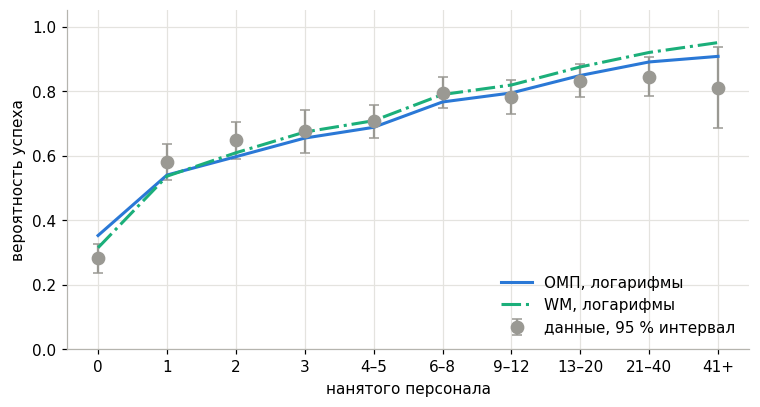

In [109]:
fig, ax = plt.subplots(figsize=(8, 4))
pos = np.arange(len(calib_log))
ax.errorbar(pos, calib_log["доля успеха"], yerr=err, fmt="o", color=GREY, ms=8, capsize=3, label="данные, 95 % интервал")
ax.plot(pos, calib_log["ОМП"], color=BLUE, lw=2, label="ОМП, логарифмы")
ax.plot(pos, calib_log["WM"], color=AQUA, lw=2, ls="-.", label="WM, логарифмы")
ax.set(xticks=pos, xticklabels=calib_log.index, xlabel="нанятого персонала", ylabel="вероятность успеха", ylim=(0, 1.05))
ax.legend(loc="lower right")
plt.show()

В логарифмах ОМП и WM расходятся заметно меньше: для персонала 0.80 и 1.03, `nepal` близок к нулю (0.04 и −0.04). Вероятности по группам лучше обеими моделями: без персонала 0.35 и 0.31 против 0.28 в данных (в исходной шкале было 0.50 и 0.41). Основную часть расхождения создавала форма зависимости. Завышение остаётся у 41+ (0.91 и 0.95 против 0.81), но в этой группе всего 37 экспедиций.

Неудач с прогнозом успеха больше 0.85 набралось 90. Из них 25 приходятся на 2015 год, когда не поднялась ни одна из 80 экспедиций: 25 апреля было землетрясение. Ещё 10 на 2014 год, доля успеха 17 %, 18 апреля сошла лавина в ледопаде Кхумбу. Пять на 2021 год, доля успеха 82 %; в примечаниях к четырём из пяти упоминается ковид, к одной тайфун. Даты это подтверждают для 2014 и 2015: в 2014 году половина весенних экспедиций закончилась к 28 апреля, в 2015 три четверти ко 2 мая, тогда как в 2013 и 2016 медиана 23–24 мая. Причина неудачи с размером экспедиции не связана, это выбросы в ответе.

Шесть из десяти самых уверенных ошибок приходятся на экспедиции 1933–1971 годов с 44–65 нанятыми: далёкие $x$ и неудача. Вес по $x$ у них 0.10–0.16, вес отклика 0.01–0.03.

Самый нетипичный успех случился летом 1980 года, 2 участника без персонала, 20 августа. Это соло-восхождение Месснера.

---
# Выводы

По данным Himalayan Database за 1921–2025 годы МНК не находит тренда персонала по годам, MM и GM находят рост на 0.9–1.1 человека за десятилетие, а с функцией масштаба $h$ рост 0.32 при SE 0.04. На 1 % экспедиций у МНК приходится 38 % квадратичной потери, в основном это ранние и крупные экспедиции с большими остатками и leverage. MM и GM согласны по знакам, но расходятся по величине. В общем положении MM устойчивее, её точка срыва 0.5, а GM проще. Здесь из-за признака `spring` точка срыва любой регрессионно эквивариантной оценки не выше 0.061.

Выбросы в линейной модели во многом созданы гетероскедастичностью: с функцией $h$ их 95 вместо 258, а SE меньше в 1.7–3.2 раза. Ещё 59 строк с нулём персонала не подтверждены отметкой `NOHIRED`, и два таких нуля стоят при погибших нанятых, то есть число просто не записано. Ошибки, посчитанные с учётом зависимости внутри года, больше сэндвича в 1.2–2.1 раза, но выводы о тренде не меняются.

В логистической модели взвешенная M-оценка подняла коэффициент при персонале с 0.063 до 0.221: далёкие неудачи, в том числе 2014 и 2015 годов, прижимали его к нулю. В логарифмах разница сократилась с 3.5 до 1.3 раза, и вероятности по группам персонала стали ближе к данным, то есть большую её часть создаёт нелинейность.

Квадратичная потеря и девианс не ограничены, бисквадрат и потеря Bianco–Yohai ограничены. Сравнивать их по профилям удобнее, чем по срезам, а полную поверхность можно нарисовать только для двух параметров.